# 10 · Web 后端实战（员工管理）


来源：[飞书讲义《10-后端Web实战(员工管理)》](https://heuqqdmbyk.feishu.cn/wiki/V2RJwKTfci4I1ek3dMzc6G72nkc)。整理日期：2026-09-29。

正文依讲义顺序保留 298 个内容块、31 段原代码和 33 张配图，并就近标注勘误与实现边界。原代码展示课程的逐步实现，不应把同名方法的不同阶段版本同时放入项目。图片以 Notebook 附件内嵌，可离线阅读；课程推广未收录。

Java、XML 和 SQL 片段应放到对应项目或数据库工具中执行，Notebook 的 Python 内核不执行这些片段。本次仅整理和静态核对笔记，未启动 Tlias 项目或数据库进行联调。


## 本章学习路线（补充）

第 09 章完成新增员工，本章把员工管理的删除与修改补齐，再统一异常响应，最后提供图表所需的统计数据。

| 环节 | 关键问题 | 主要技术 |
| --- | --- | --- |
| 批量删除 | 多个 ID 如何绑定并同时删除两张表的数据？ | `DELETE /emps`、`@RequestParam`、`<foreach>`、事务 |
| 查询回显 | 一次查询如何还原员工及多条工作经历？ | 左连接、MyBatis `resultMap` 与 `<collection>` |
| 修改员工 | 怎样更新基本信息并替换工作经历？ | `PUT /emps`、动态 SQL、事务 |
| 异常处理 | 唯一约束冲突后怎样返回统一格式？ | `@RestControllerAdvice`、`@ExceptionHandler` |
| 报表数据 | 怎样生成职位与性别的图表数据？ | `GROUP BY`、`CASE`/`IF`、`/report` 接口 |

本章继续沿用前几章的 Controller → Service → Mapper 分层。统计接口只提供数据，图表渲染属于前端。


我们已经完成了员工管理中的列表查询、新增员工的功能，那关于员工管理还有两个功能分别是：修改员工、删除员工。

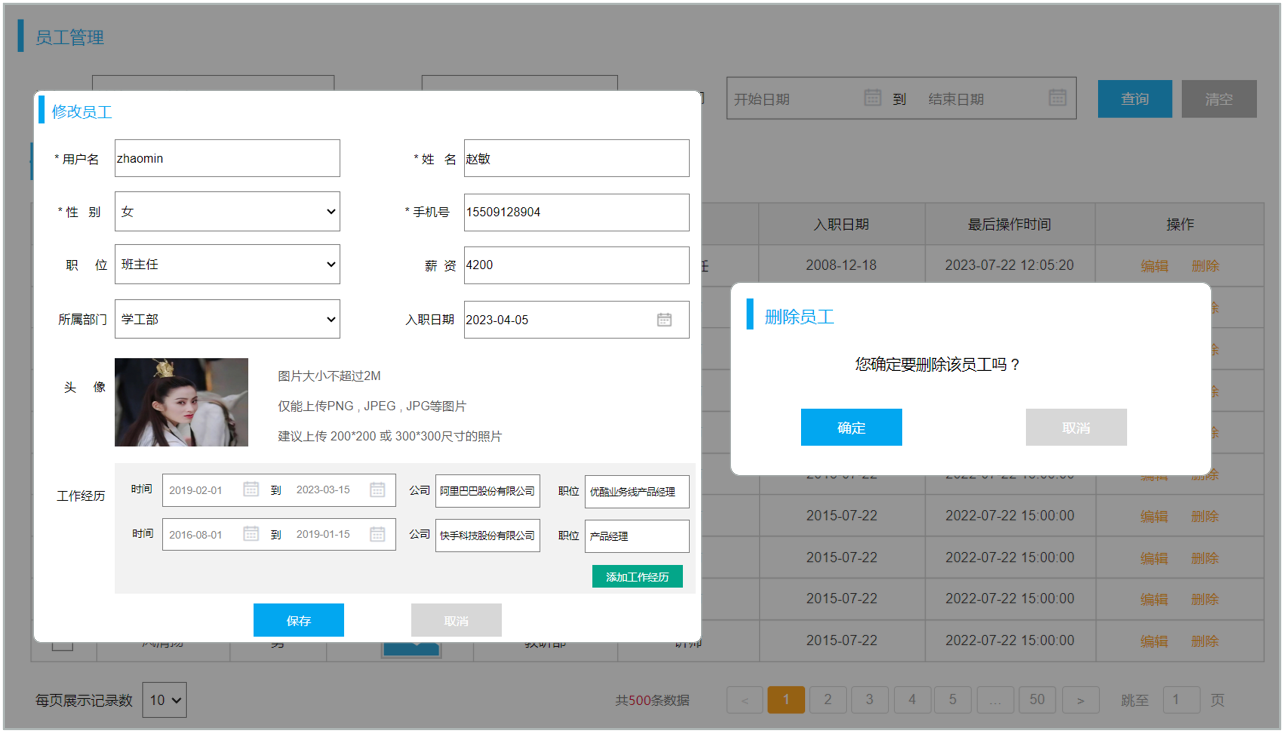

除了员工管理的功能以外，我们还要完成员工信息统计的功能，包括：员工职位统计、员工性别统计。

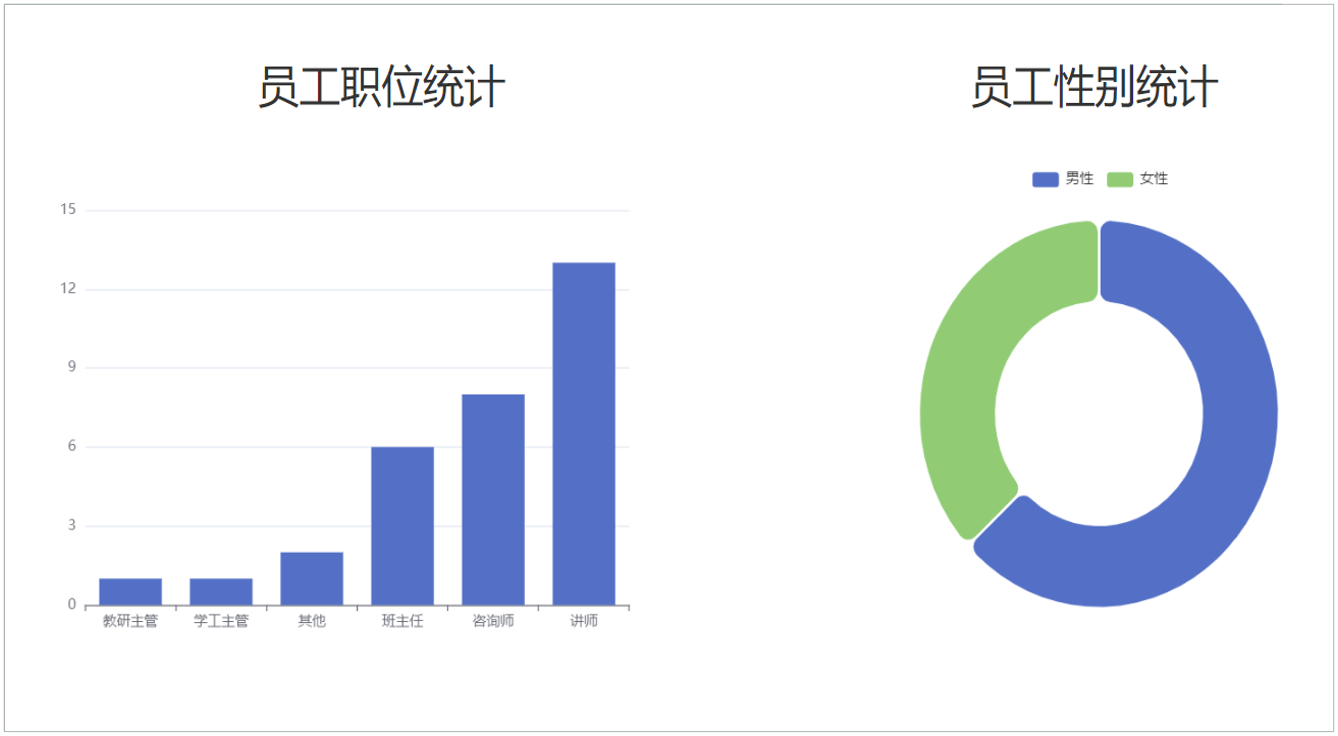

所以，今天课程内容包含如下几个部分：

- 删除员工
- 修改员工
- 异常处理
- 员工信息统计


## 1 删除员工


### 1.1 需求

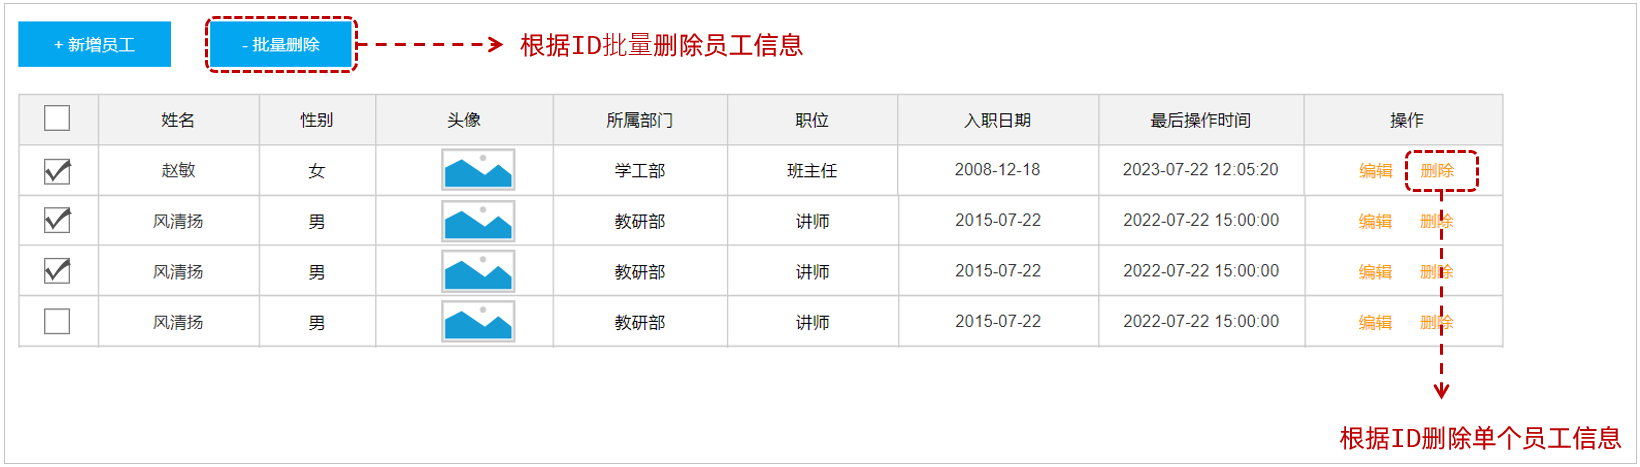

当我们勾选列表前面的复选框，然后点击 "批量删除" 按钮，就可以将这一批次的员工信息删除掉了。也可以只勾选一个复选框，仅删除一个员工信息。

问题：我们需要开发两个功能接口吗？一个删除单个员工，一个删除多个员工

答案：不需要。 只需要开发一个功能接口即可（删除多个员工包含只删除一个员工）


### 1.2 接口文档

参照资料中提供的接口文档，查看 <strong><code>员工管理</code></strong>  -&gt; <strong><code>删除员工</code></strong><strong> </strong>接口的描述。


### 1.3 思路分析

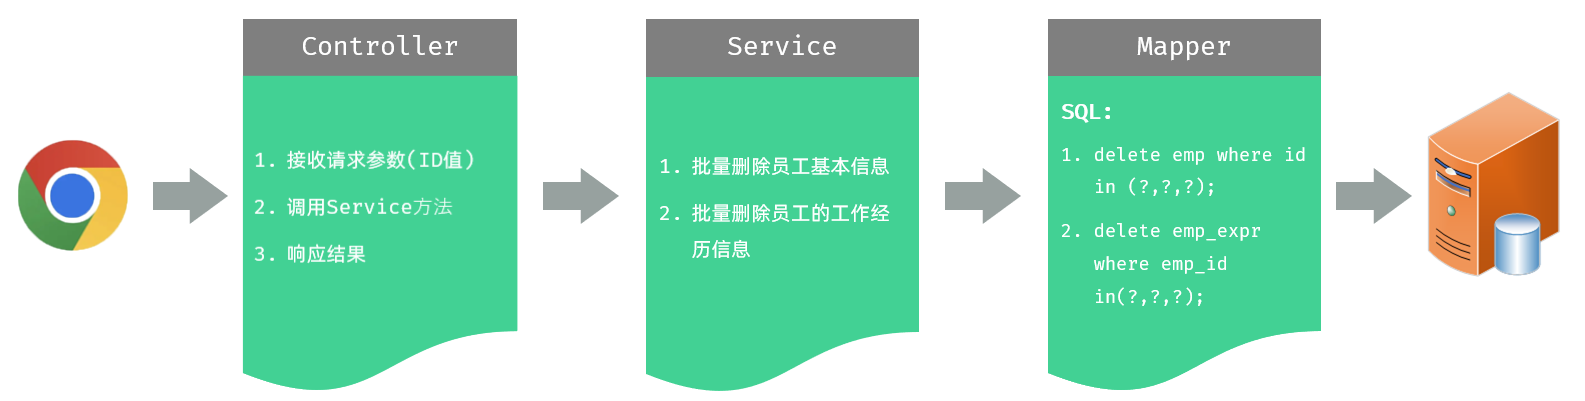


### 1.4 功能开发


#### 1.4.1 Controller接收参数

在 <code>EmpController</code> 中增加如下方法 <code>delete</code> ，来执行批量删除员工的操作。

<strong>方式一：在Controller方法中通过数组来接收</strong>

多个参数，默认可以将其封装到一个数组中，需要保证前端传递的参数名 与 方法形参名称保持一致。

````java
/**
* 批量删除员工
*/
@DeleteMapping
public Result delete(Integer[] ids){
    log.info("批量删除部门: ids={} ", Arrays.asList(ids));
    return Result.success();
}
````

<strong>方式二：</strong><strong>在Controller方法中通过集合来接收</strong>

也可以将其封装到一个List&lt;Integer&gt; 集合中，如果要将其封装到一个集合中，需要在集合前面加上 <code>@RequestParam</code> 注解。

````java
/**
* 批量删除员工
*/
@DeleteMapping
public Result delete(@RequestParam List<Integer> ids){
    log.info("批量删除部门: ids={} ", ids);
    empService.deleteByIds(ids);
    return Result.success();
}
````

**补充｜请求参数。** 本章的删除接口接收 URL 查询参数，如 `DELETE /emps?ids=1,2`；`@RequestParam List<Integer> ids` 使绑定意图明确。入口应拒绝空列表，避免后续 `<foreach>` 生成 `IN ()`。日志中的“部门”是讲义笔误，应为“员工”。

两种方式，选择其中一种就可以，我们一般推荐选择集合，因为基于集合操作其中的元素会更加方便。


#### 1.4.2 Service

1). 在接口中 <code>EmpService</code> 中定义接口方法 <code>deleteByIds</code>

````java
/**
* 批量删除员工
*/
void deleteByIds(List<Integer> ids);
````

2). 在实现类 <code>EmpServiceImpl</code> 中实现接口方法 <code>deleteByIds</code>

在删除员工信息时，既需要删除 emp 表中的员工基本信息，还需要删除 emp&#95;expr 表中员工的工作经历信息

````java
@Transactional
@Override
public void deleteByIds(List<Integer> ids) {
    //1. 根据ID批量删除员工基本信息
    empMapper.deleteByIds(ids);

    //2. 根据员工的ID批量删除员工的工作经历信息
    empExprMapper.deleteByEmpIds(ids);
}
````

**补充｜事务与删除顺序。** 两张表的删除应位于同一事务。若 `emp_expr.emp_id` 有指向 `emp.id` 的外键且未配置级联删除，应先删工作经历，再删员工；讲义先删员工的顺序会触发外键约束。批量删除前还要校验 `ids` 非空。

由于删除员工信息，既要删除员工基本信息，又要删除工作经历信息，操作多次数据库的删除，所以需要进行事务控制。


#### 1.4.3 Mapper

1). 在 <code>EmpMapper</code> 接口中增加 <code>deleteByIds</code> 方法实现批量删除员工基本信息

````java
/**
* 批量删除员工信息
*/
void deleteByIds(List<Integer> ids);
````

2). 在 <code>EmpMapper.xml</code> 配置文件中, 配置对应的SQL语句

````xml
<!--批量删除员工信息-->
<delete id="deleteByIds">
    delete from emp where id in
    <foreach collection="ids" item="id" open="(" close=")" separator=",">
            #{id}
    </foreach>
</delete>
````

**补充｜Mapper 参数名。** XML 使用 `collection="ids"` 时，建议把接口参数显式写为 `@Param("ids") List<Integer> ids`；工作经历 Mapper 的 `empIds` 同理。这样不依赖编译器是否保留形参名。

3). 在 <code>EmpExprMapper</code> 接口中增加 <code>deleteByEmpIds</code> 方法实现根据员工ID批量删除员工的工作经历信息

````java
/**
* 根据员工的ID批量删除工作经历信息
*/
void deleteByEmpIds(List<Integer> empIds);
````

4). 在 <code>EmpExprMapper.xml</code> 配置文件中, 配置对应的SQL语句

````xml
<!--根据员工的ID批量删除工作经历信息-->
<delete id="deleteByEmpIds">
    delete from emp_expr where emp_id in
    <foreach collection="empIds" item="empId" open="(" close=")" separator=",">
            #{empId}
    </foreach>
</delete>
````


### 1.5 功能测试

功能开发完成后，重启项目工程，打开 Apifox，发起DELETE请求：

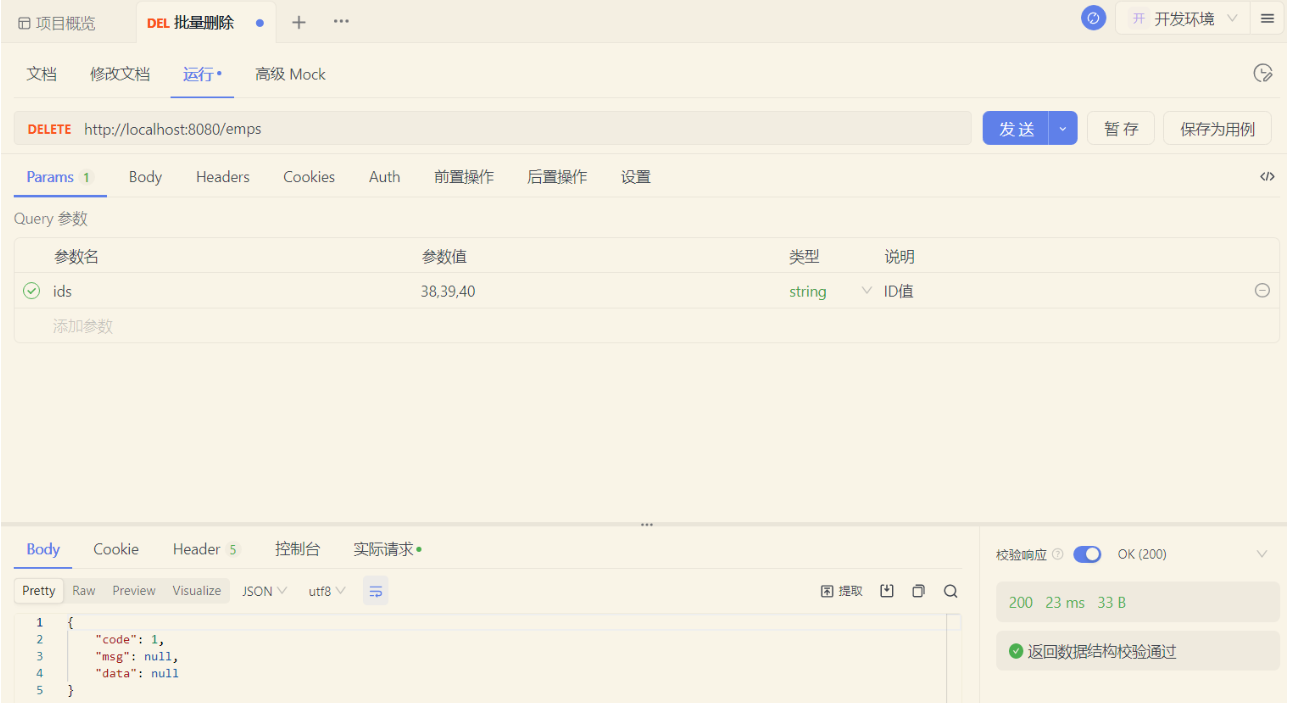

控制台SQL语句：

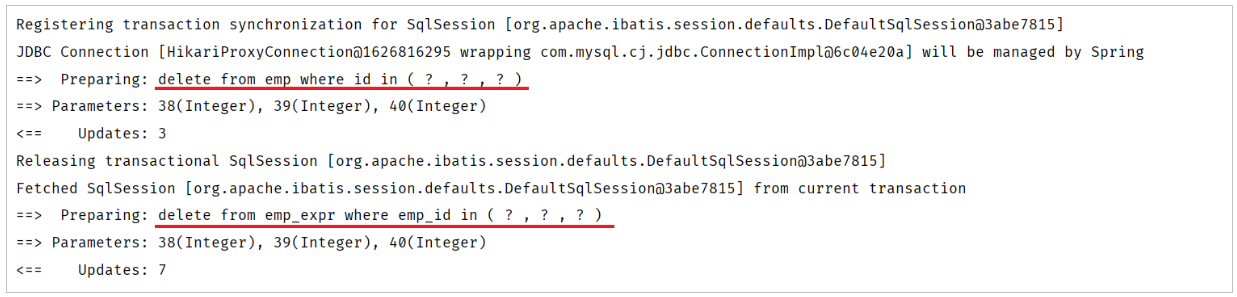


### 1.6 前后端联调

打开浏览器，测试后端功能接口：

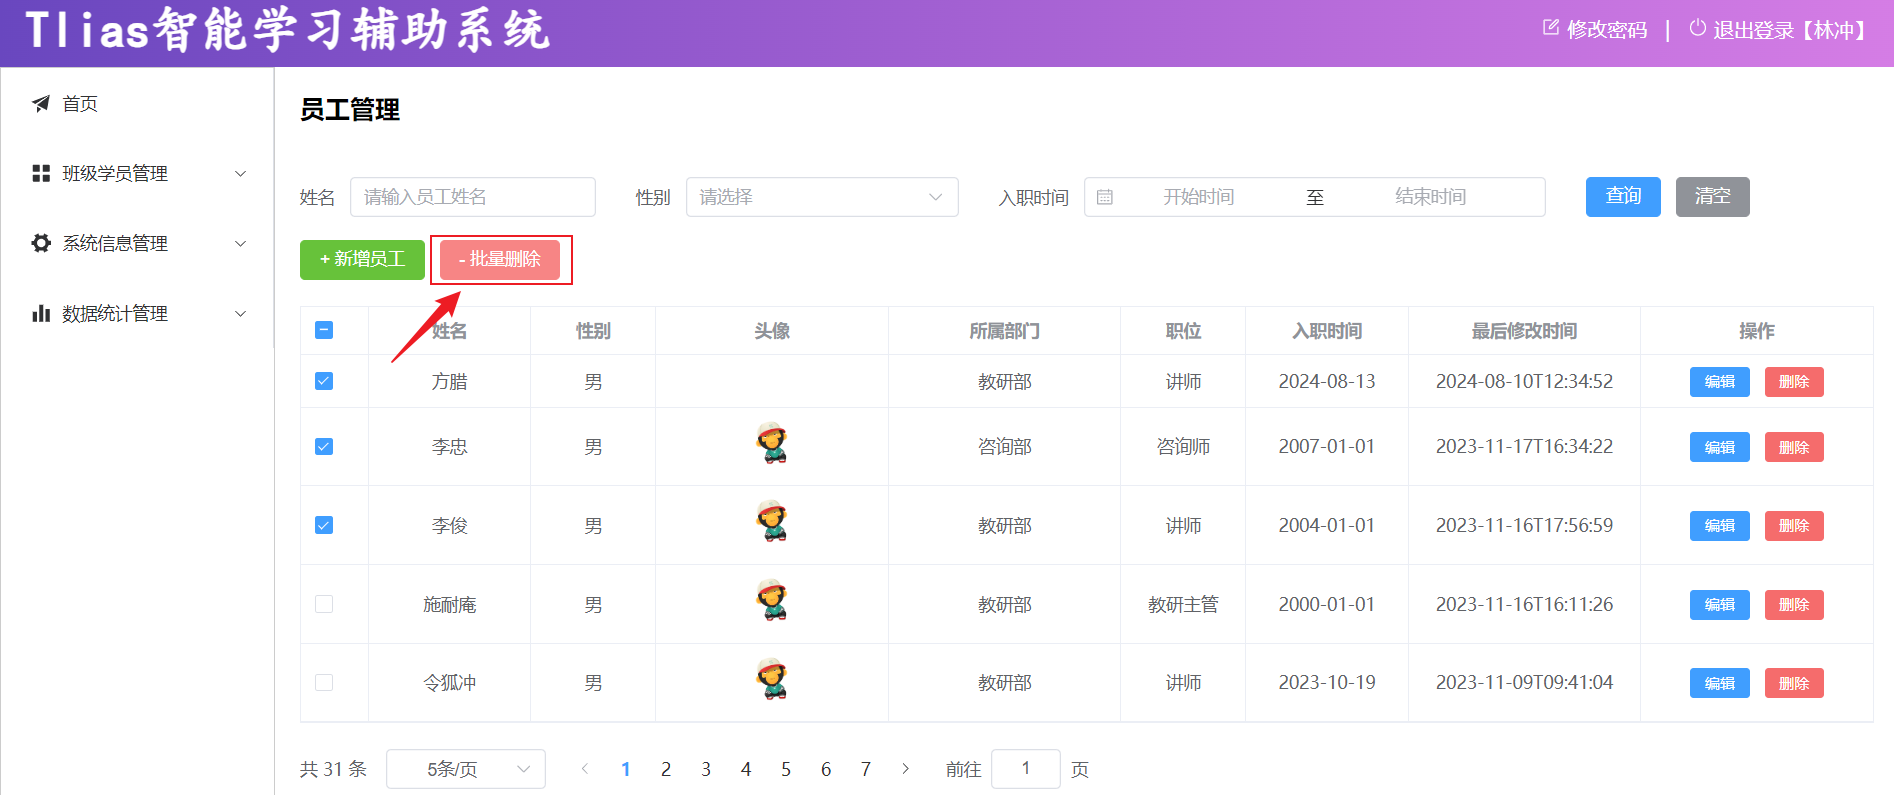


## 2 修改员工

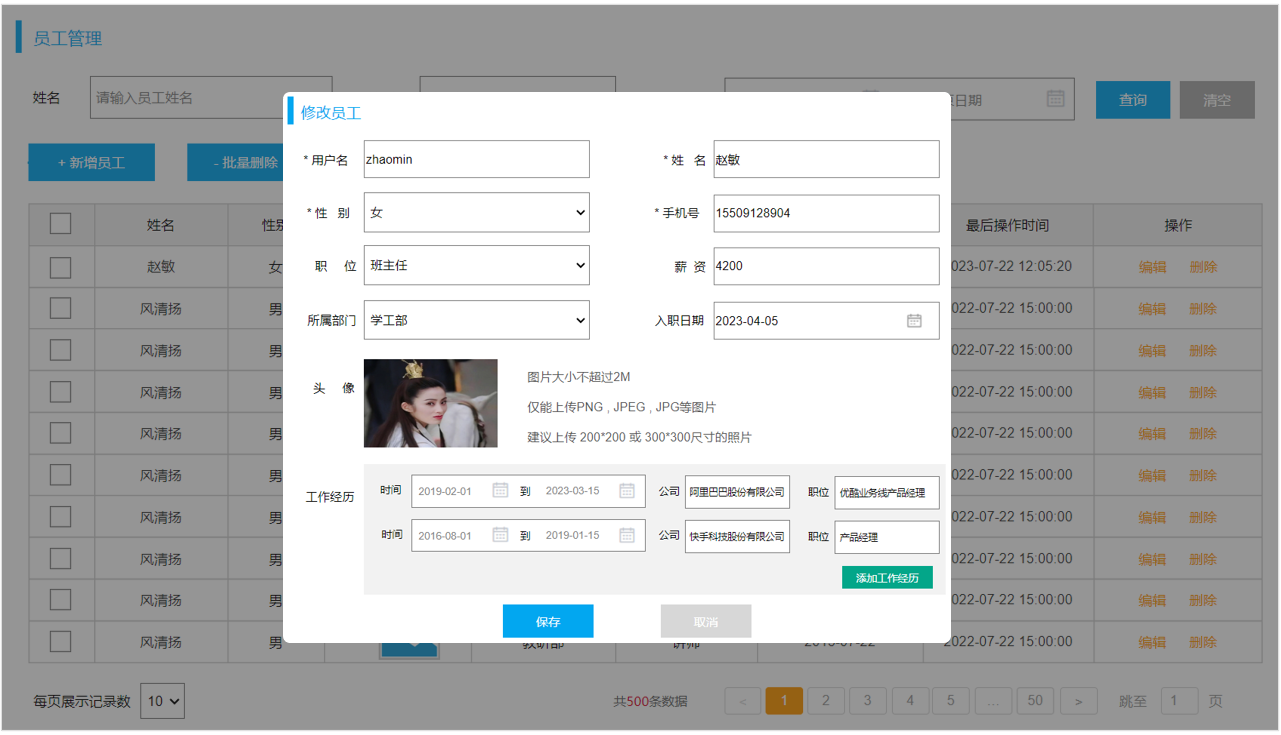

在进行修改员工信息的时候，我们首先先要根据员工的ID查询员工的详细信息用于页面回显展示，然后用户修改员工数据之后，点击保存按钮，就可以将修改的数据提交到服务端，保存到数据库。 具体操作为：

1\. 根据ID查询员工信息

2\. 保存修改的员工信息


### 2.1 查询回显


#### 2.1.1 接口描述

参照资料中提供的接口文档，查看 <strong><code>员工管理</code></strong>  -&gt; <strong><code>根据ID查询</code></strong><strong> </strong>接口的描述。


#### 2.1.2 思路

在查询回显时，既需要查询出员工的基本信息，又需要查询出该员工的工作经历信息。 

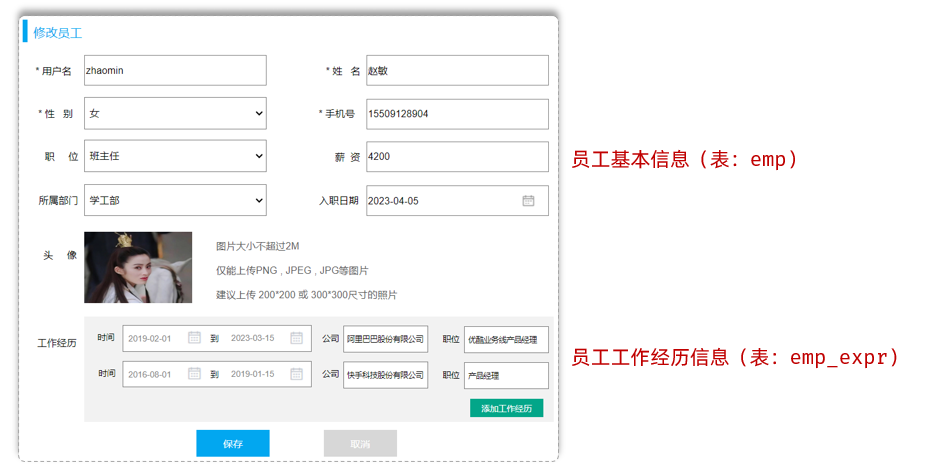

我们可以先通过一条SQL语句，查询出指定员工的基本信息，及其员工的工作经历信息。SQL如下：

````sql
select e.*,
       ee.id ee_id,
       ee.begin ee_begin,
       ee.end ee_end,
       ee.company ee_company,
       ee.job ee_job
from emp e left join emp_expr ee on e.id = ee.emp_id where e.id = 39;
````

具体的实现思路如下：

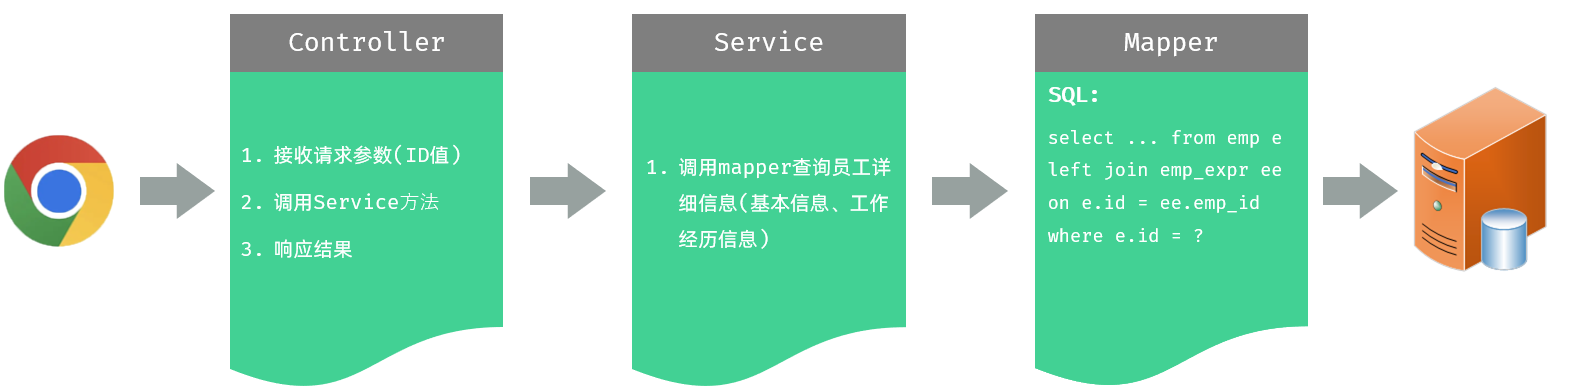


#### 2.1.3 代码实现

1). <code>EmpController</code> 添加 <code>getInfo</code> 用来根据ID查询员工数据，用于页面回显 

````java
/**
 * 查询回显
 */
@GetMapping("/{id}")
public Result getInfo(@PathVariable Integer id){
    log.info("根据id查询员工的详细信息");
    Emp emp  = empService.getInfo(id);
    return Result.success(emp);
}
````

2). <code>EmpService</code> 接口中增加 <code>getInfo</code> 方法

````java
/**
 * 根据ID查询员工的详细信息
 */
Emp getInfo(Integer id);
````

3). <code>EmpServiceImpl</code> 实现类中实现 &#96;getInfo&#96; 方法

````java
@Override
public Emp getInfo(Integer id) {
    return empMapper.getById(id);
}
````

4). <code>EmpMapper</code> 接口中增加 <code>getById</code> 方法

````java
/**
 * 根据ID查询员工详细信息
 */
Emp getById(Integer id);
````

5).  <code>EmpMapper.xml</code> 配置文件中定义对应的SQL

````xml
<!--自定义结果集ResultMap-->
<resultMap id="empResultMap" type="com.itheima.pojo.Emp">
    <id column="id" property="id" />
    <result column="username" property="username" />
    <result column="password" property="password" />
    <result column="name" property="name" />
    <result column="gender" property="gender" />
    <result column="phone" property="phone" />
    <result column="job" property="job" />
    <result column="salary" property="salary" />
    <result column="image" property="image" />
    <result column="entry_date" property="entryDate" />
    <result column="dept_id" property="deptId" />
    <result column="create_time" property="createTime" />
    <result column="update_time" property="updateTime" />

    <!--封装exprList-->
    <collection property="exprList" ofType="com.itheima.pojo.EmpExpr">
        <id column="ee_id" property="id"/>
        <result column="ee_company" property="company"/>
        <result column="ee_job" property="job"/>
        <result column="ee_begin" property="begin"/>
        <result column="ee_end" property="end"/>
        <result column="ee_empid" property="empId"/>
    </collection>
</resultMap>

<!--根据ID查询员工的详细信息-->
<select id="getById" resultMap="empResultMap">
    select e.*,
        ee.id ee_id,
        ee.emp_id ee_empid,
        ee.begin ee_begin,
        ee.end ee_end,
        ee.company ee_company,
        ee.job ee_job
    from emp e left join emp_expr ee on e.id = ee.emp_id
    where e.id = #{id}
</select>
````

**补充｜敏感字段。** 讲义的回显查询包含 `password`，若直接把 `Emp` 返回前端会暴露密码字段。实际项目应返回专用响应 DTO 或至少排除密码，并只保存密码哈希。`<collection>` 中的 `ee_id` 用作子记录主键，可避免左连接无工作经历时生成无效子对象。

在这种一对多的查询中，我们要想成功的封装的结果，需要手动的基于 <code>&lt;resultMap&gt;</code> 来进行封装结果。

> Mybatis中封装查询结果，什么时候用 resultType，什么时候用resultMap ？
> 
> - 如果查询返回的字段名与实体的属性名可以直接对应上，用resultType 。
> - 如果查询返回的字段名与实体的属性名对应不上，或实体属性比较复杂，可以通过resultMap手动封装 。


#### 2.1.4 Apifox测试

重新启动服务，基于Apifox进行接口测试。

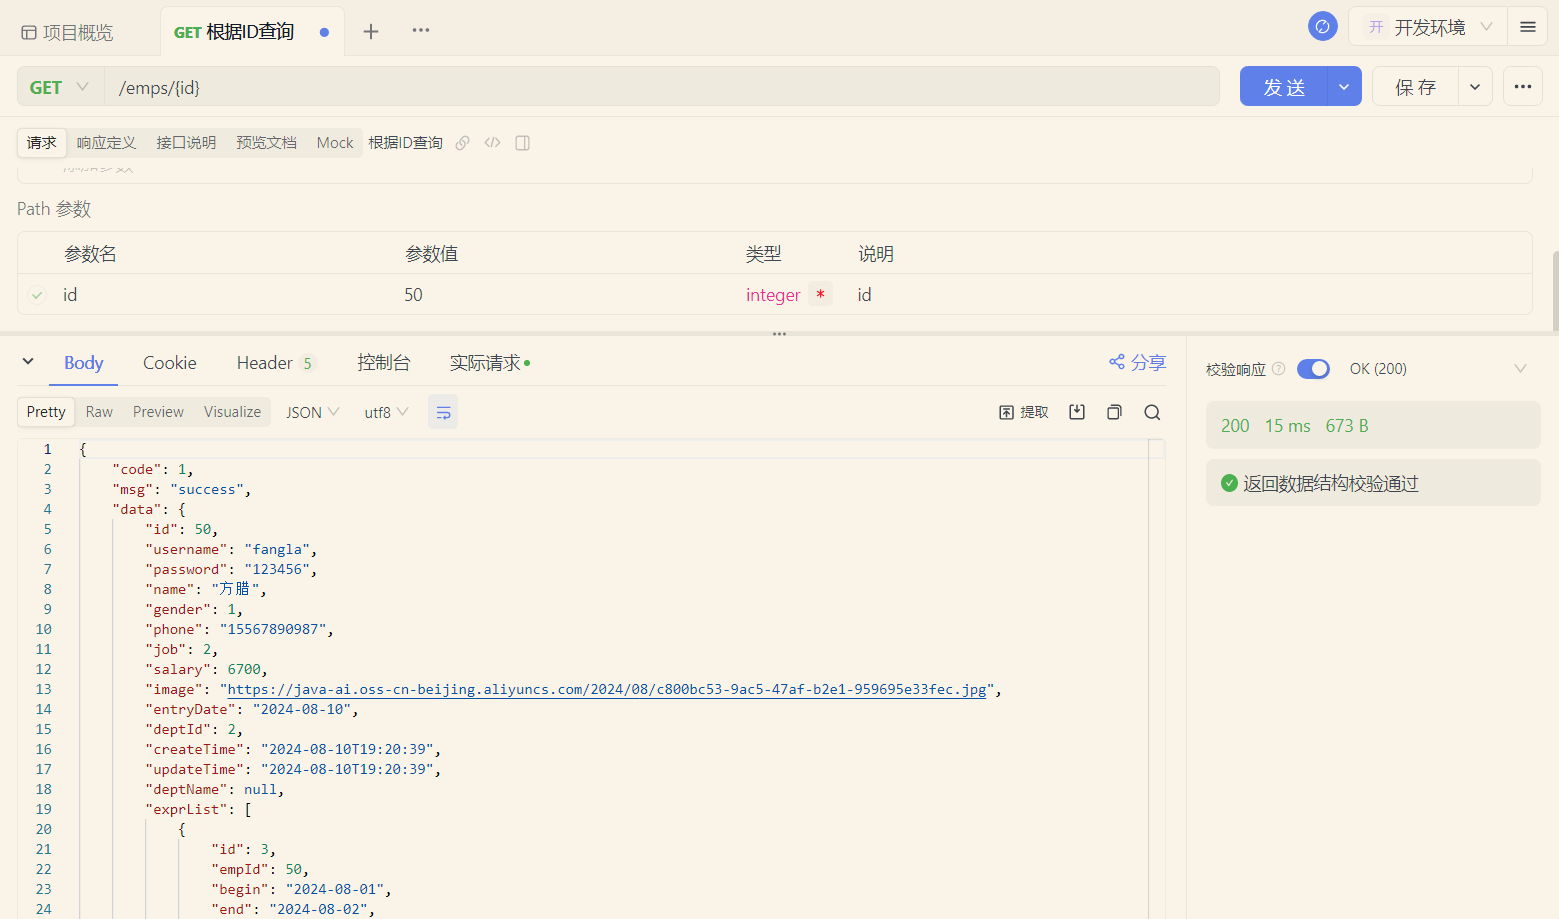


#### 2.1.5 前后端联调测试

打开浏览器，进行前后端联调测试。

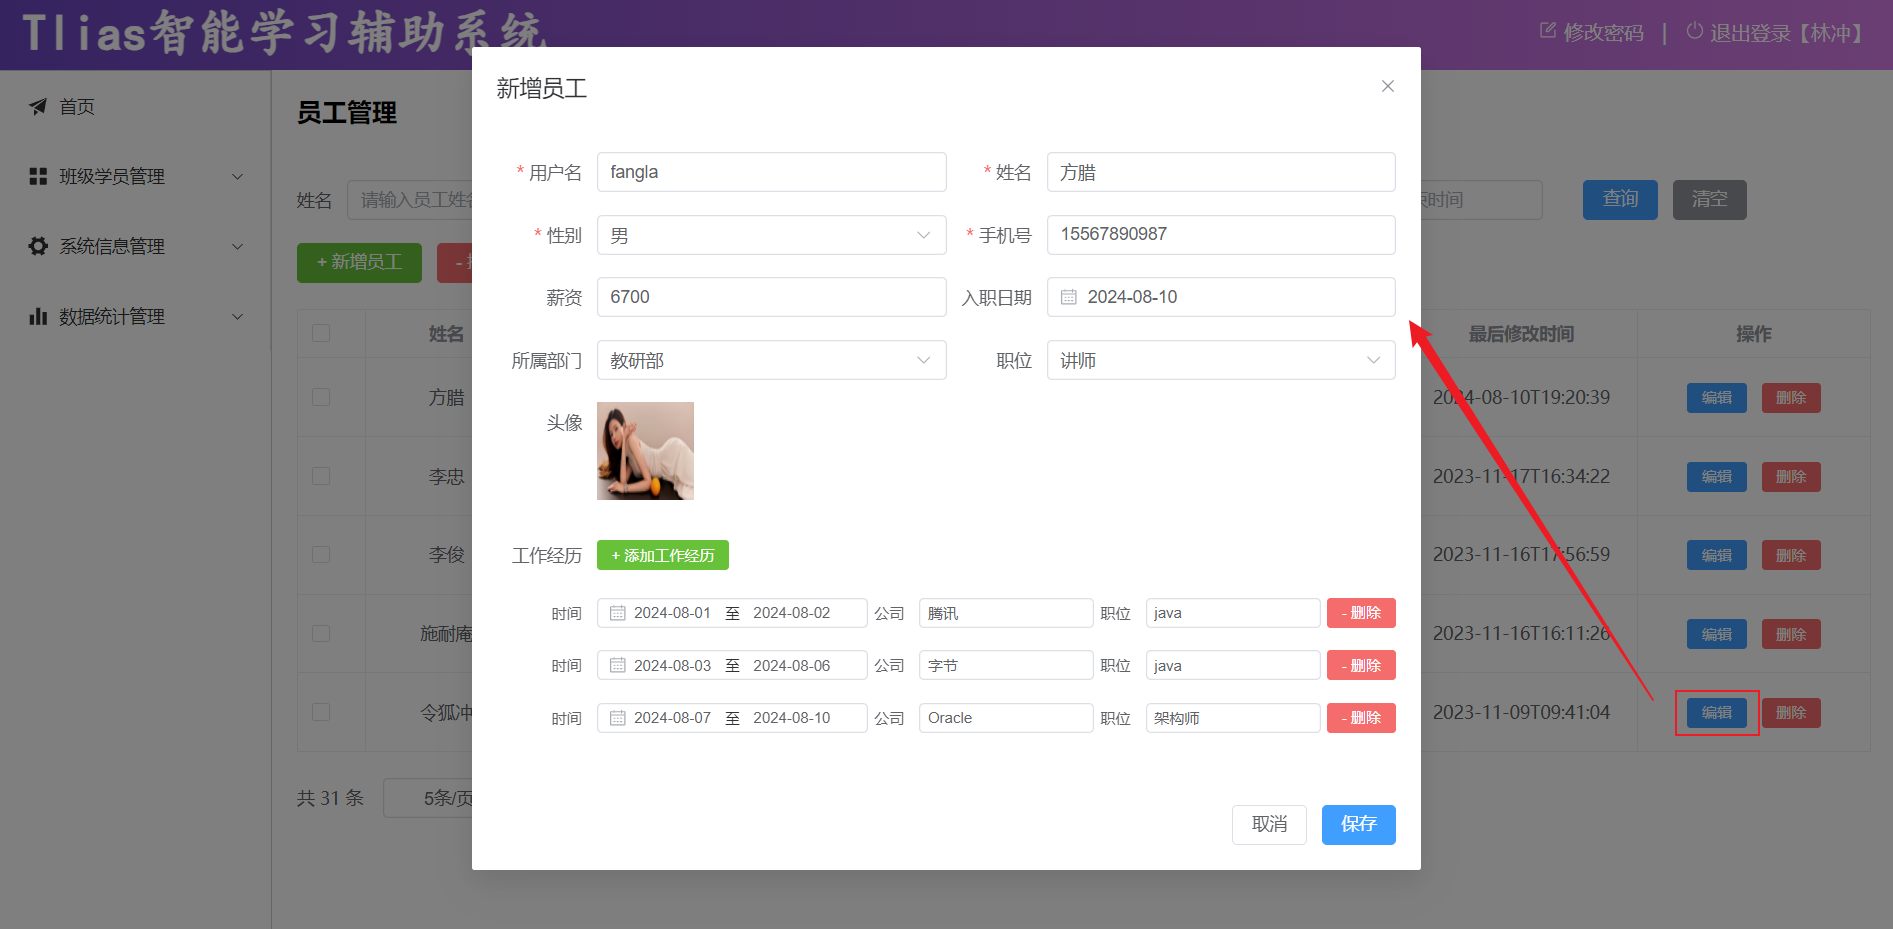


### 2.2 修改员工

查询回显之后，就可以在页面上修改员工的信息了。

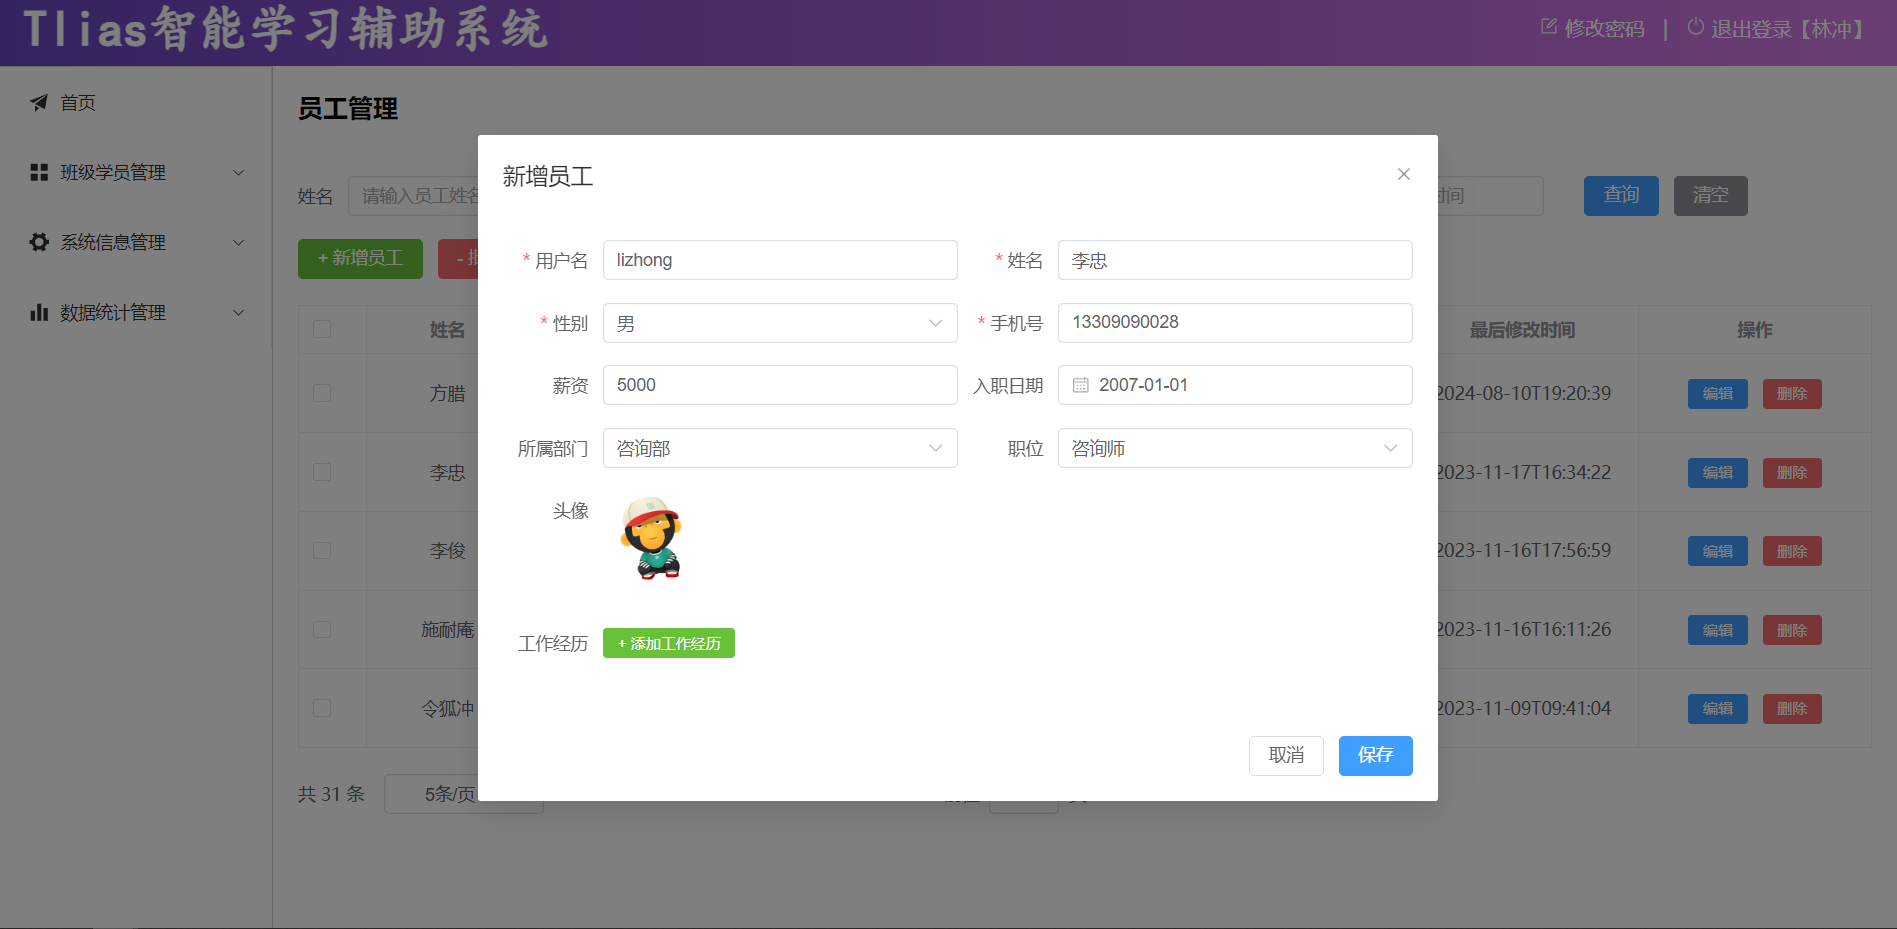

- 当用户修改完数据之后，点击保存按钮，就需要将数据提交到服务端，然后服务端需要将修改后的数据更新到数据库中 。 
- 而此次更新的时候，既需要更新员工的基本信息； 又需要更新员工的工作经历信息 。


#### 2.2.1 接口文档

参照资料中提供的接口文档，查看 <strong><code>员工管理</code></strong>  -&gt; <strong><code>修改员工</code></strong><strong> </strong>接口的描述。


#### 2.2.2 实现思路

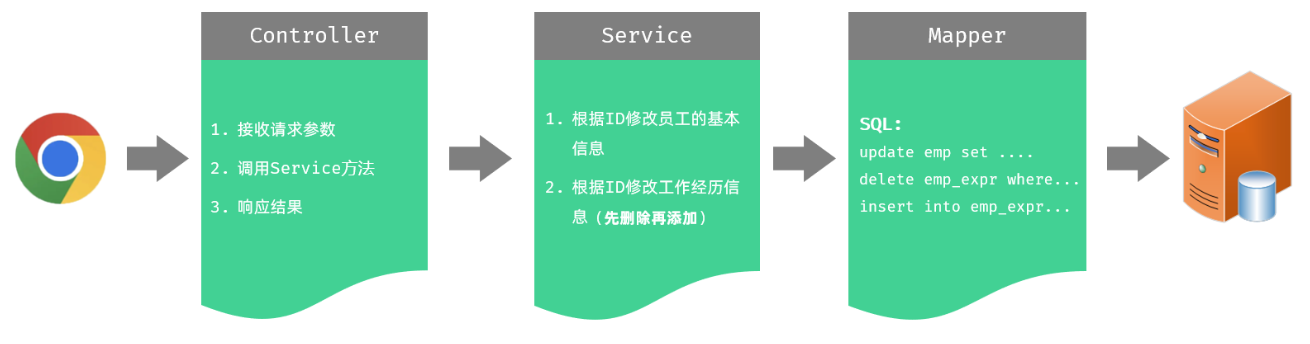


#### 2.2.3 代码实现

1). <code>EmpController</code> 增加 <code>update</code> 方法接收请求参数，响应数据

````java
/**
* 更新员工信息
*/
@PutMapping
public Result update(@RequestBody Emp emp){
    log.info("修改员工信息, {}", emp);
    empService.update(emp);
    return Result.success();
}
````

2). <code>EmpService</code> 接口增加 <code>update</code> 方法

````java
/**
* 更新员工信息
* @param emp
*/
void update(Emp emp);
````

3).  <code>EmpServiceImpl</code>实现类实现 <code>update</code> 方法

````java
@Transactional
@Override
public void update(Emp emp) {
    //1. 根据ID更新员工基本信息
    emp.setUpdateTime(LocalDateTime.now());
    empMapper.updateById(emp);

    //2. 根据员工ID删除员工的工作经历信息 【删除老的】
    empExprMapper.deleteByEmpIds(Arrays.asList(emp.getId()));

    //3. 新增员工的工作经历数据 【新增新的】
    Integer empId = emp.getId();
    List<EmpExpr> exprList = emp.getExprList();
    if(!CollectionUtils.isEmpty(exprList)){
        exprList.forEach(empExpr -> empExpr.setEmpId(empId));
        empExprMapper.insertBatch(exprList);
    }
}
````

**补充｜覆盖语义。** 这段实现先删除全部旧工作经历，再插入新列表，因此 `exprList` 为 `null` 或空列表都会清空经历。只有在接口明确约定“整组覆盖”时才这样做；若 `null` 表示“不修改”，应先判断是否传入该字段。员工基本信息与经历更新须一起回滚。

4). <code>EmpMapper</code> 接口中增加 <code>updateById</code> 方法

````java
/**
* 更新员工基本信息
*/
void updateById(Emp emp);
````

5). <code>EmpMapper.xml</code> 配置文件中定义对应的SQL语句，基于动态SQL更新员工信息

````xml
<!--根据ID更新员工信息-->
<update id="updateById">
    update emp
    <set>
        <if test="username != null and username != ''">username = #{username},</if>
        <if test="password != null and password != ''">password = #{password},</if>
        <if test="name != null and name != ''">name = #{name},</if>
        <if test="gender != null">gender = #{gender},</if>
        <if test="phone != null and phone != ''">phone = #{phone},</if>
        <if test="job != null">job = #{job},</if>
        <if test="salary != null">salary = #{salary},</if>
        <if test="image != null and image != ''">image = #{image},</if>
        <if test="entryDate != null">entry_date = #{entryDate},</if>
        <if test="deptId != null">dept_id = #{deptId},</if>
        <if test="updateTime != null">update_time = #{updateTime},</if>
    </set>
    where id = #{id}
</update>
````

**补充｜动态 SQL 边界。** 这些 `<if>` 会跳过 `null` 和部分空字符串，因此无法通过当前接口清空手机号、头像等字段。讲义的 Service 会设置 `updateTime`，所以只传 ID 时仍可能执行一次没有业务字段变化的更新；请按接口约定区分“未传”和“主动清空”，并校验至少有一项业务字段可更新。


#### 2.2.4 Apifox测试

重新启动服务，打开 Apifox 进行接口测试。

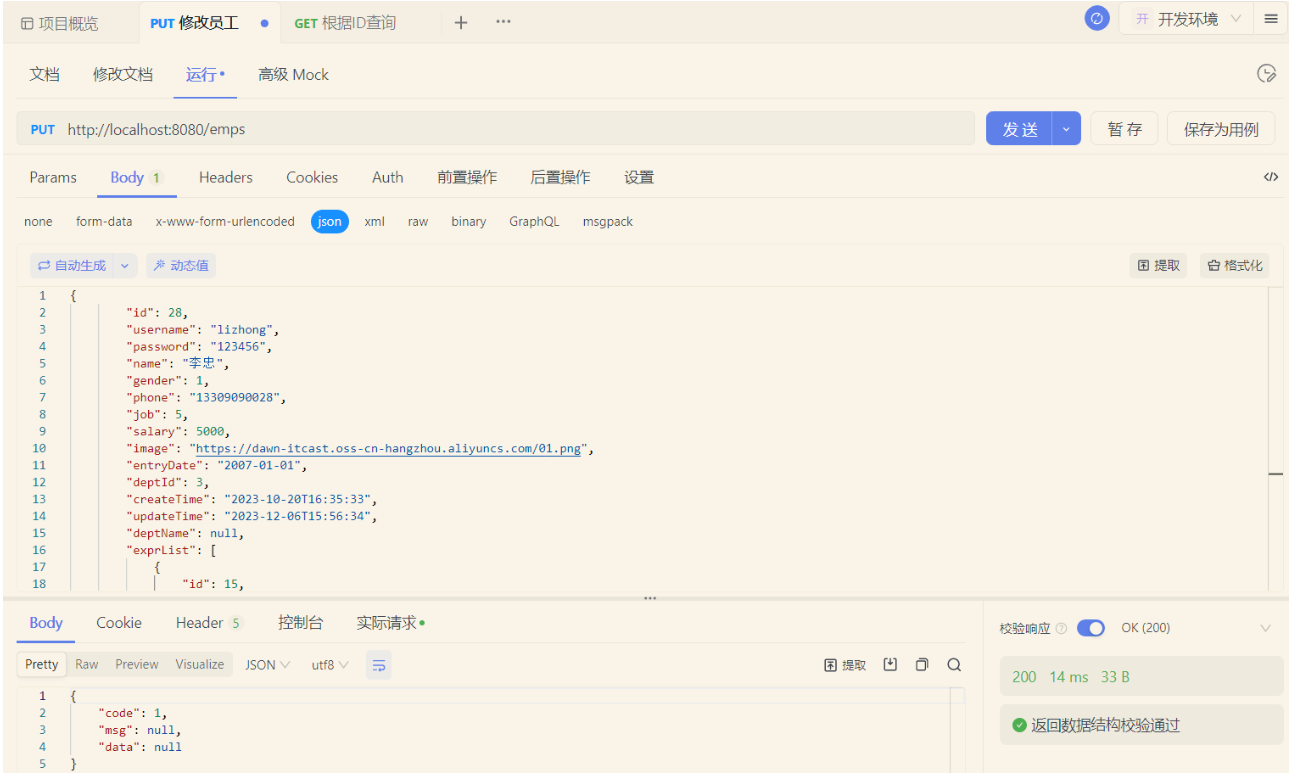


#### 2.2.5 前后端联调

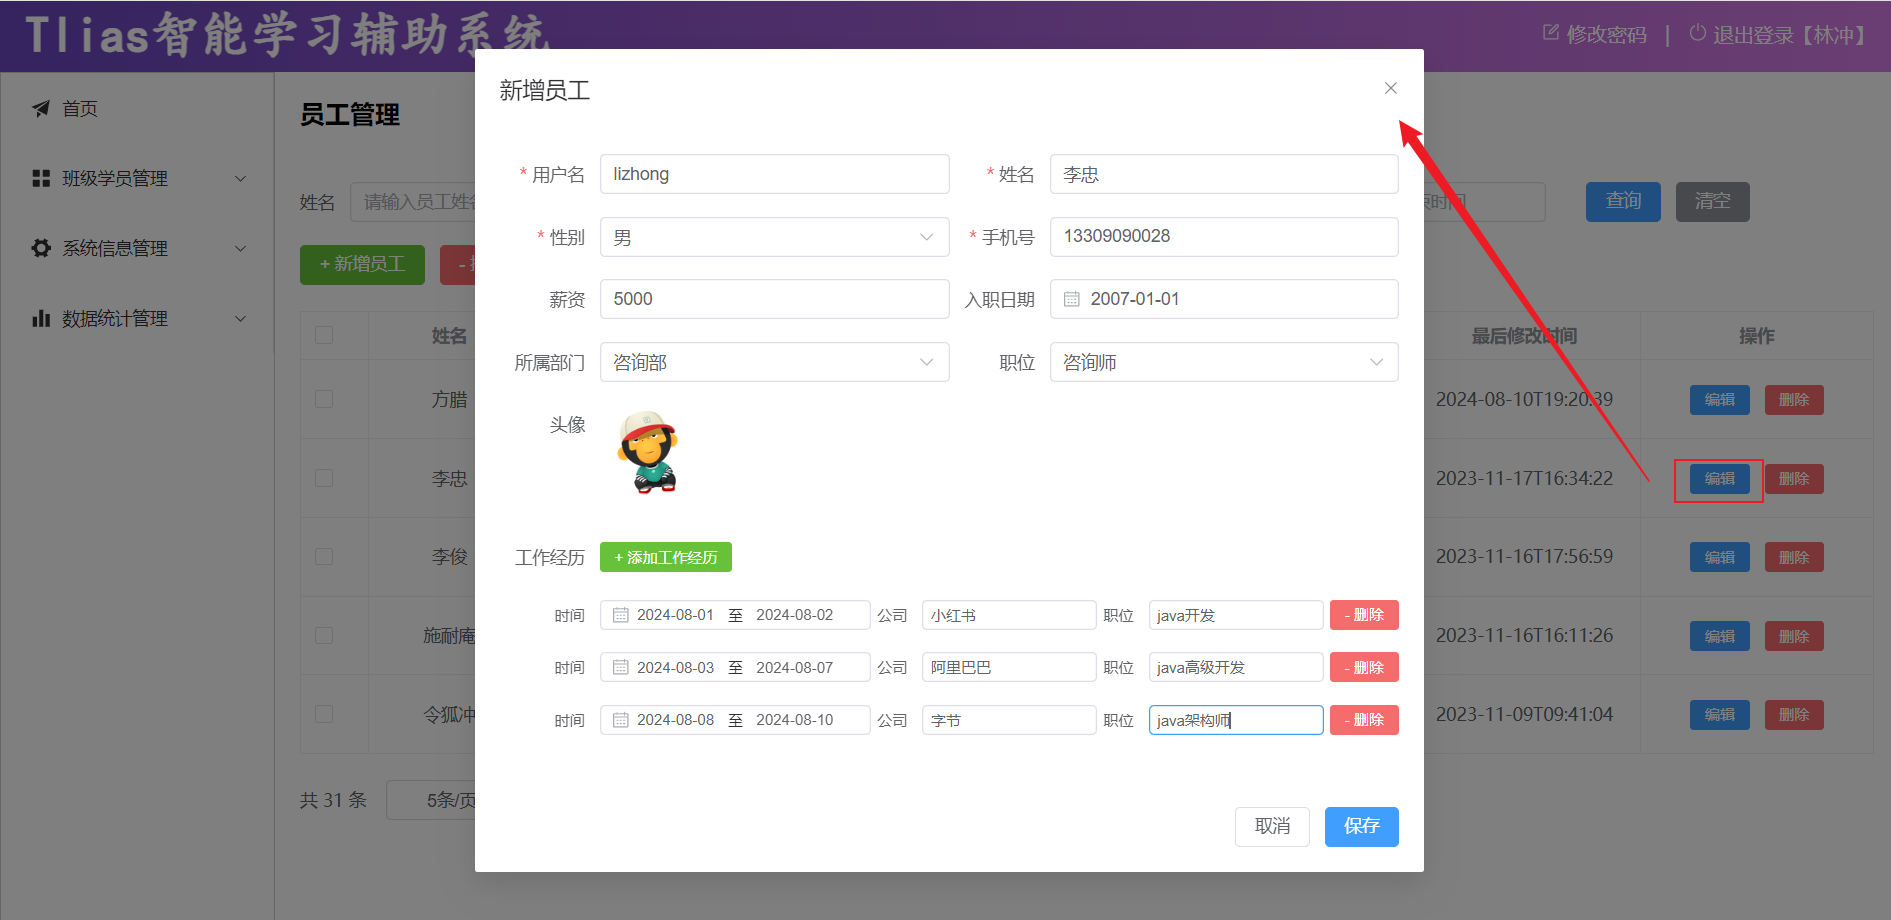

点击保存之后，查看更新后的数据。

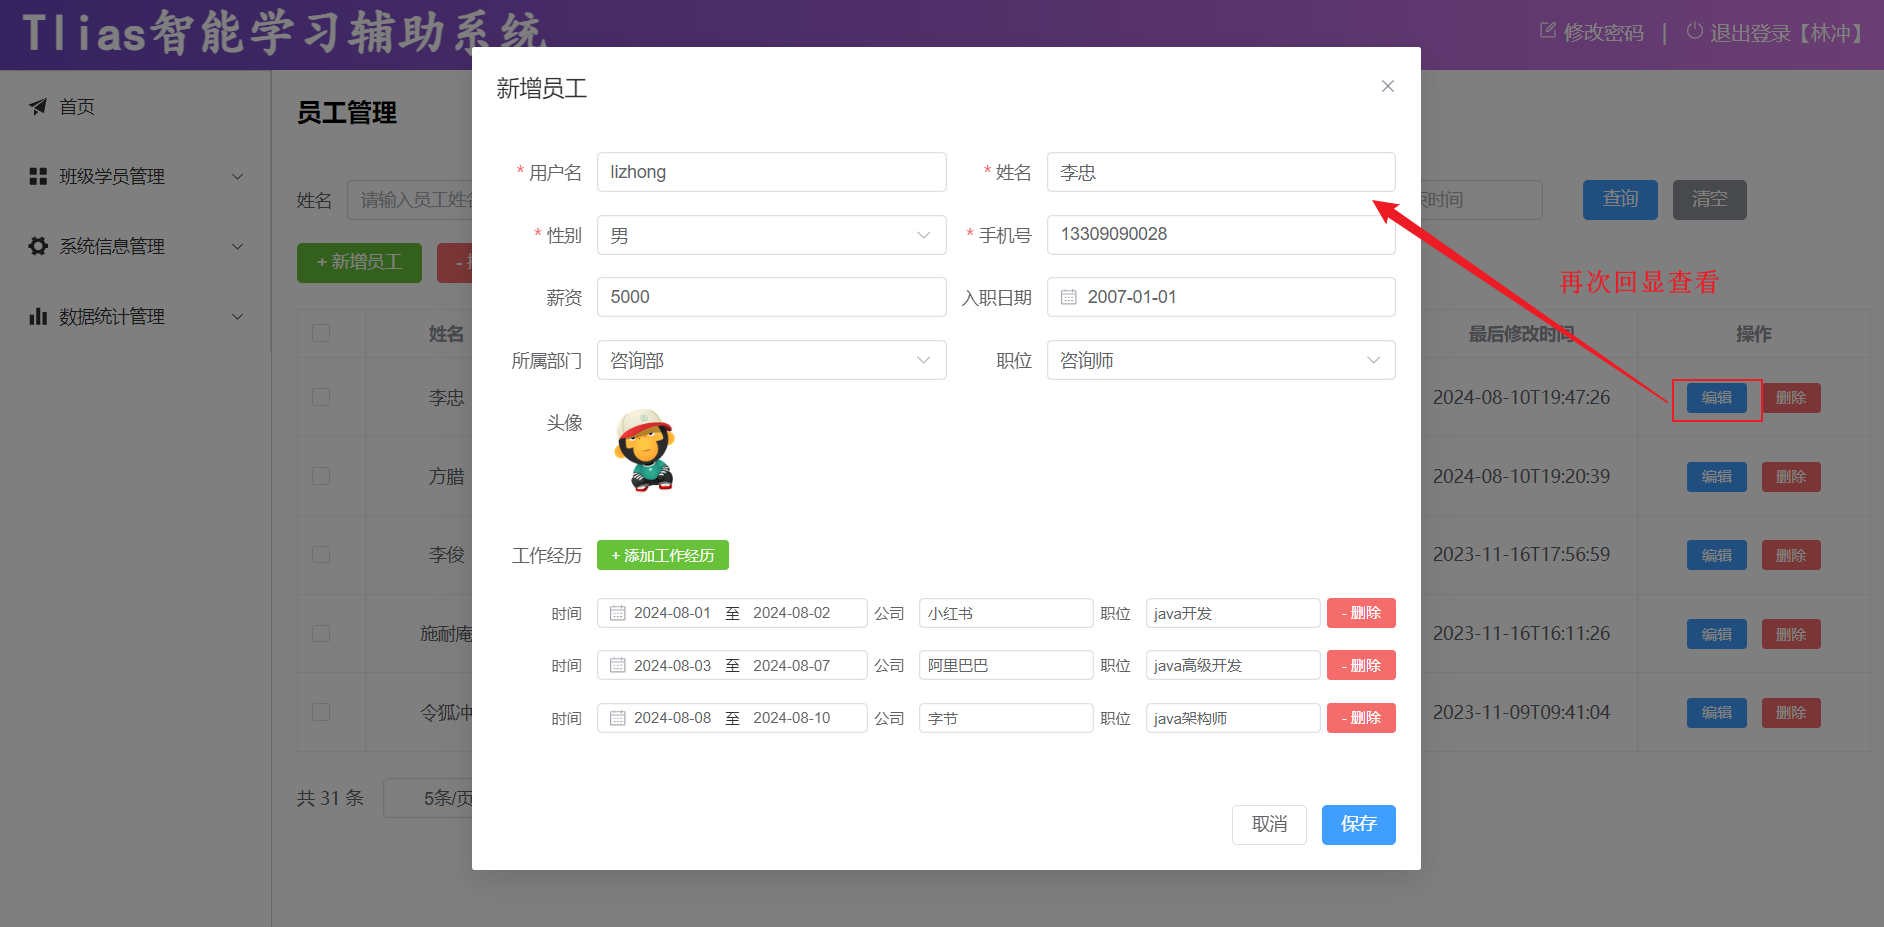


## 3 异常处理


### 3.1 问题分析

当我们在修改部门数据的时候，如果输入一个在数据库表中已经存在的手机号，点击保存按钮之后，前端提示了错误信息，但是返回的结果并不是统一的响应结果，而是框架默认返回的错误结果 。

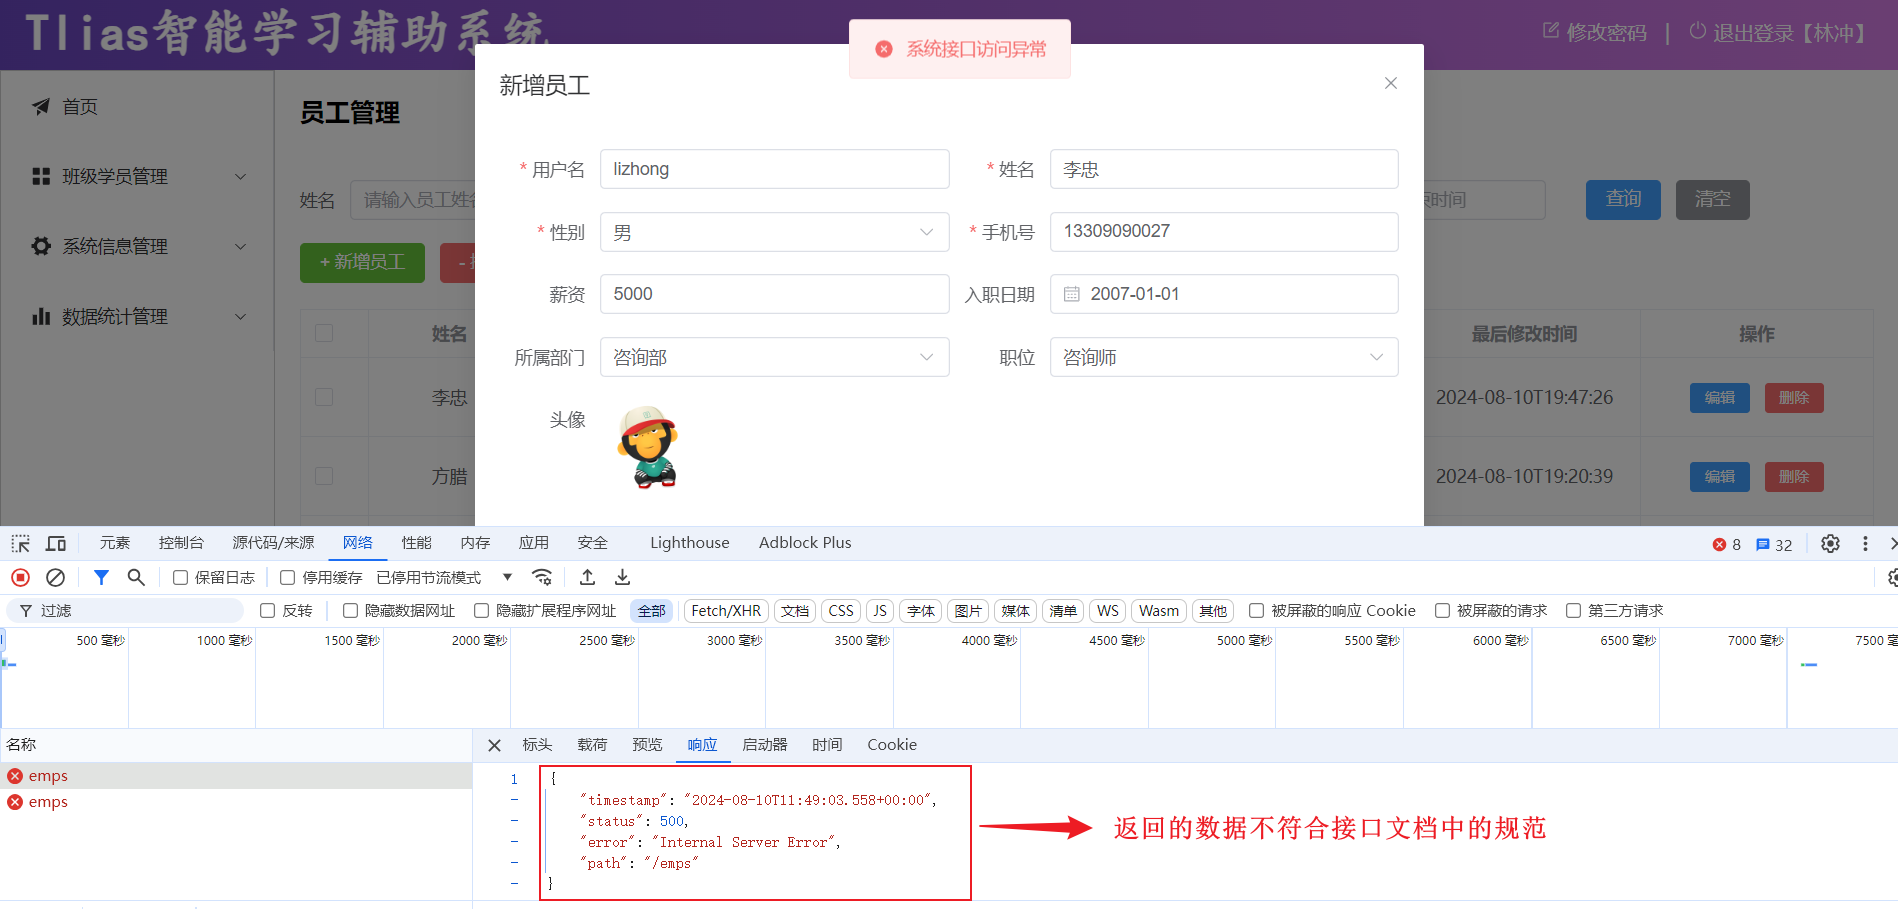

状态码为500，表示服务器端异常，我们打开idea，来看一下，服务器端出了什么问题。

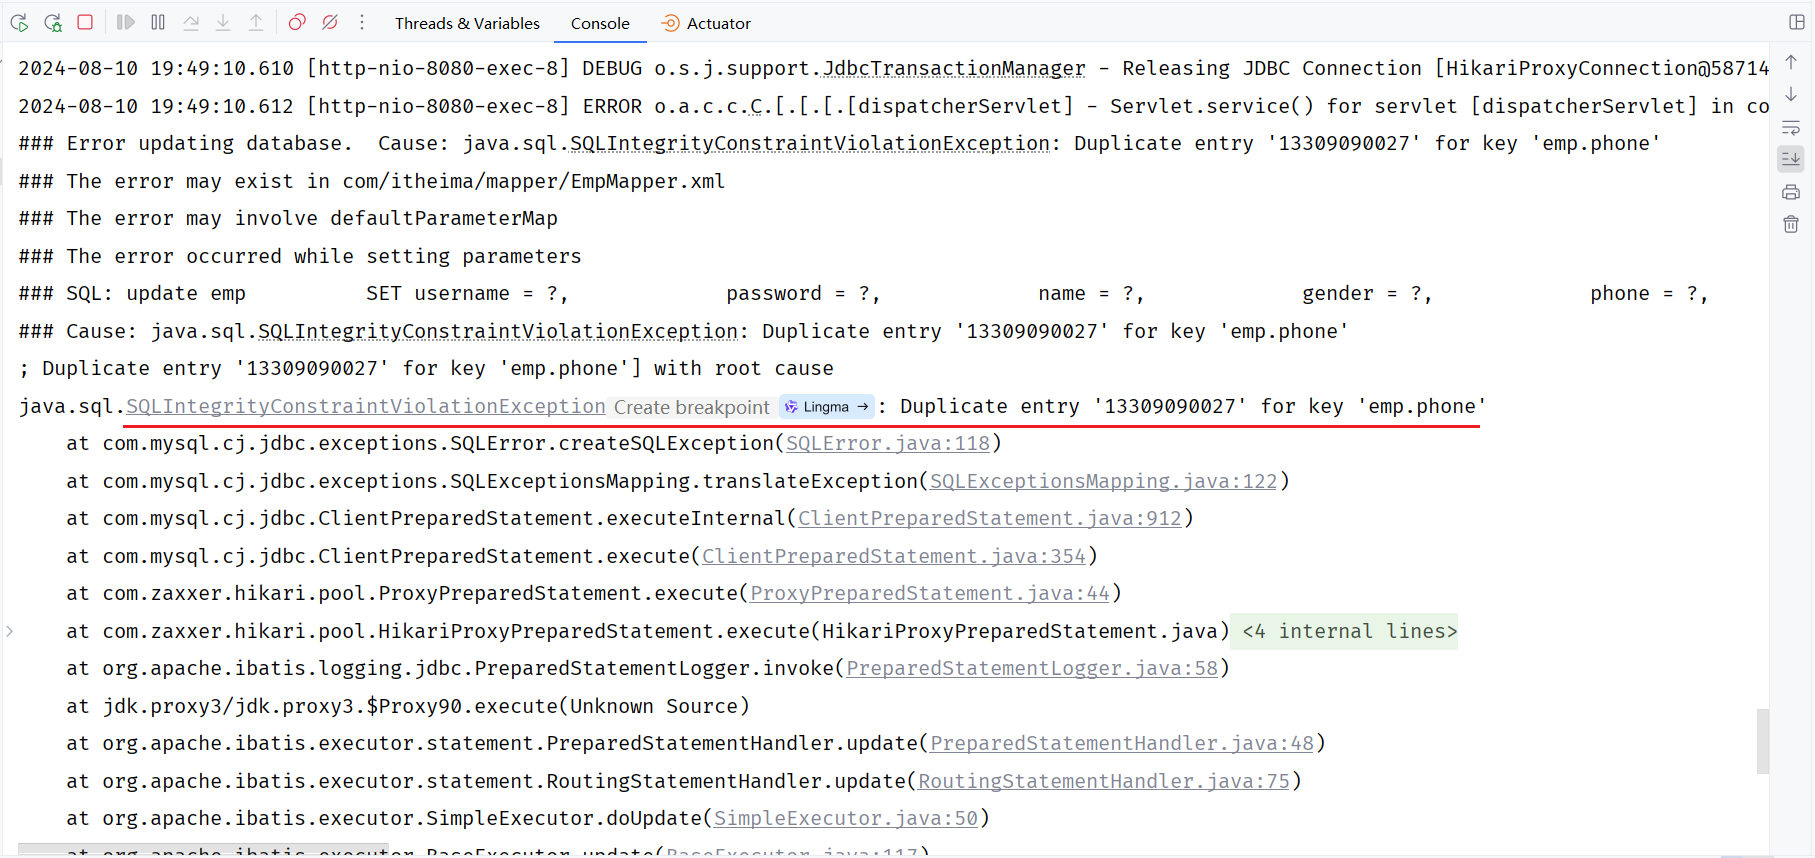

上述错误信息的含义是，<code>emp</code>员工表的<code>phone</code>手机号字段的值重复了，因为在数据库表<code>emp</code>中已经有了<code>13309090027</code>这个手机号了，我们之前设计这张表时，为<code>phone</code>字段建议了唯一约束，所以该字段的值是不能重复的。

而当我们再将该员工的手机号也设置为 <code>13309090027</code>，就违反了唯一约束，此时就会报错。

我们来看一下出现异常之后，最终服务端给前端响应回来的数据长什么样。

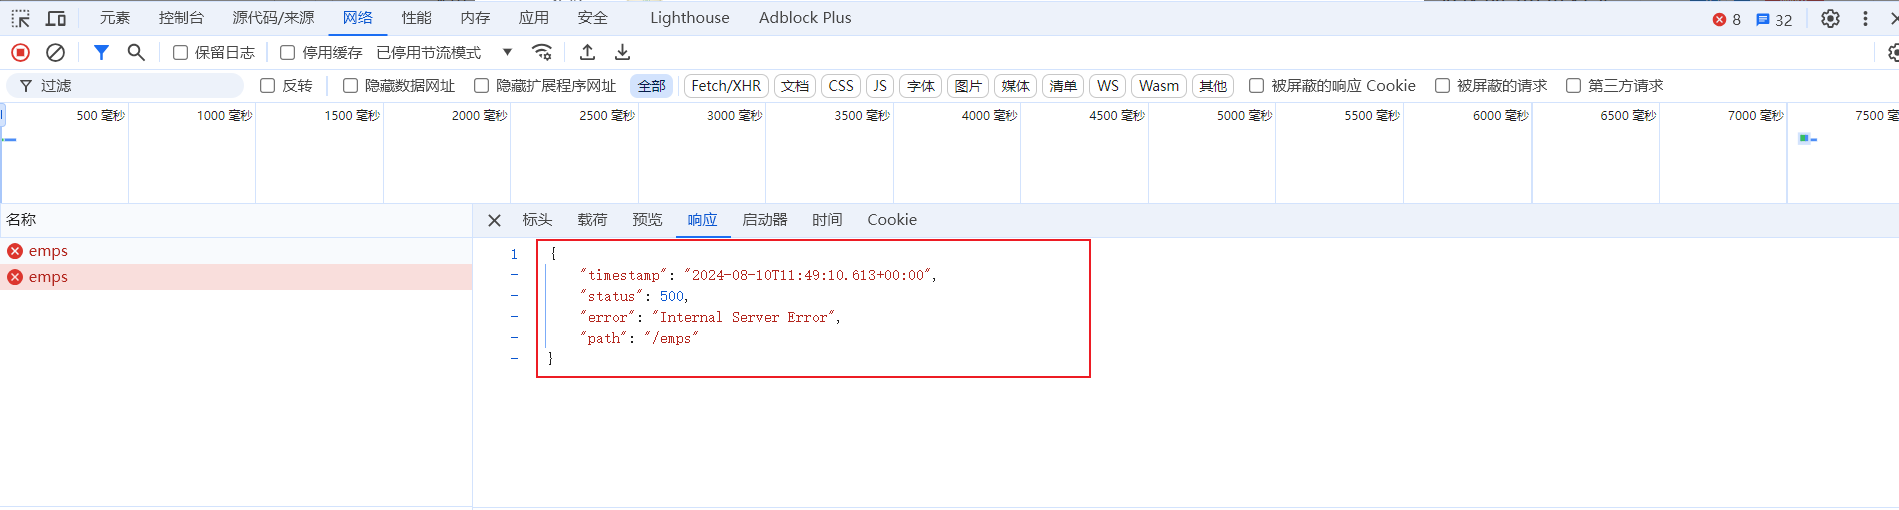

响应回来的数据是一个JSON格式的数据。但这种JSON格式的数据还是我们开发规范当中所提到的统一响应结果Result吗？显然并不是。由于返回的数据不符合开发规范，所以前端并不能解析出响应的JSON数据 。

接下来我们需要思考的是出现异常之后，当前案例项目的异常是怎么处理的？ 答案：没有做任何的异常处理

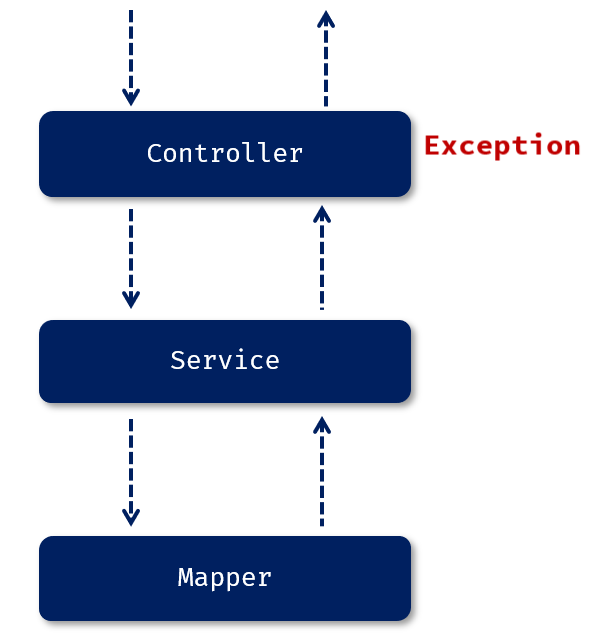

当我们没有做任何的异常处理时，我们三层架构处理异常的方案：

- Mapper接口在操作数据库的时候出错了，此时异常会往上抛(谁调用Mapper就抛给谁)，会抛给service。 
- service 中也存在异常了，会抛给controller。
- 而在controller当中，我们也没有做任何的异常处理，所以最终异常会再往上抛。最终抛给框架之后，框架就会返回一个JSON格式的数据，里面封装的就是错误的信息，但是框架返回的JSON格式的数据并不符合我们的开发规范。


### 3.2 解决方案

那么在三层构架项目中，出现了异常，该如何处理? 

- <strong>方案一：在所有Controller的所有方法中进行try…catch处理</strong>

 缺点：代码臃肿（不推荐）

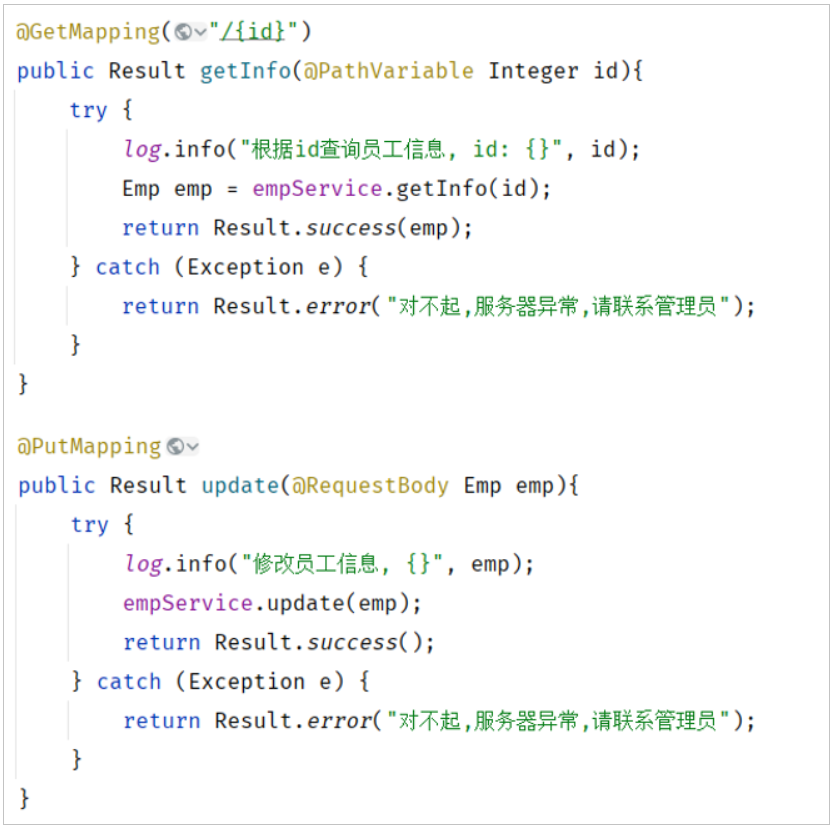

- <strong>方案二：</strong><strong>全局异常处理器</strong>

好处：简单、优雅（推荐）

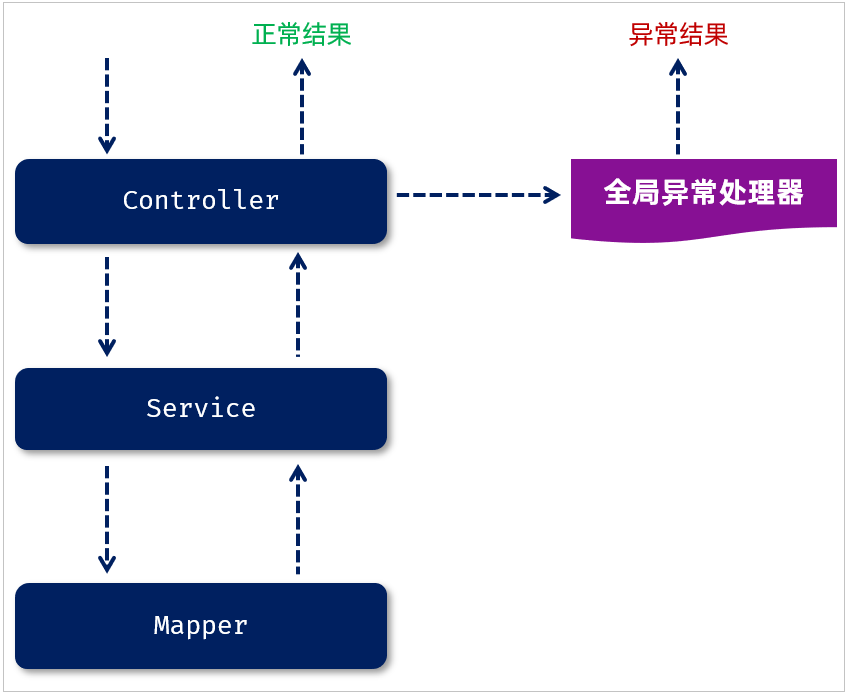


### 3.3 全局异常处理器

我们该怎么样定义全局异常处理器？

- 定义全局异常处理器非常简单，就是定义一个类，在类上加上一个注解@RestControllerAdvice，加上这个注解就代表我们定义了一个全局异常处理器。
- 在全局异常处理器当中，需要定义一个方法来捕获异常，在这个方法上需要加上注解@ExceptionHandler。通过@ExceptionHandler注解当中的value属性来指定我们要捕获的是哪一类型的异常。

````java
@RestControllerAdvice
public class GlobalExceptionHandler {
    
    //处理异常
    @ExceptionHandler
    public Result ex(Exception e){//方法形参中指定能够处理的异常类型
        e.printStackTrace();//打印堆栈中的异常信息
        //捕获到异常之后，响应一个标准的Result
        return Result.error("对不起,操作失败,请联系管理员");
    }
    
}
````

**补充｜异常分层。** `Exception` 兜底处理可以保证统一响应，但生产代码应使用日志记录堆栈，针对参数校验、唯一键冲突等定义更具体的处理；不要把数据库异常详情返回给前端。若系统约定使用 HTTP 状态码表达错误，也应设置相应状态。

> @RestControllerAdvice = @ControllerAdvice + @ResponseBody
> 
> 处理异常的方法返回值会转换为json后再响应给前端

重新启动SpringBoot服务，打开浏览器，再来测试一下 修改员工 这个操作，我们依然设置已存在的 <code>13309090027</code>这个手机号：

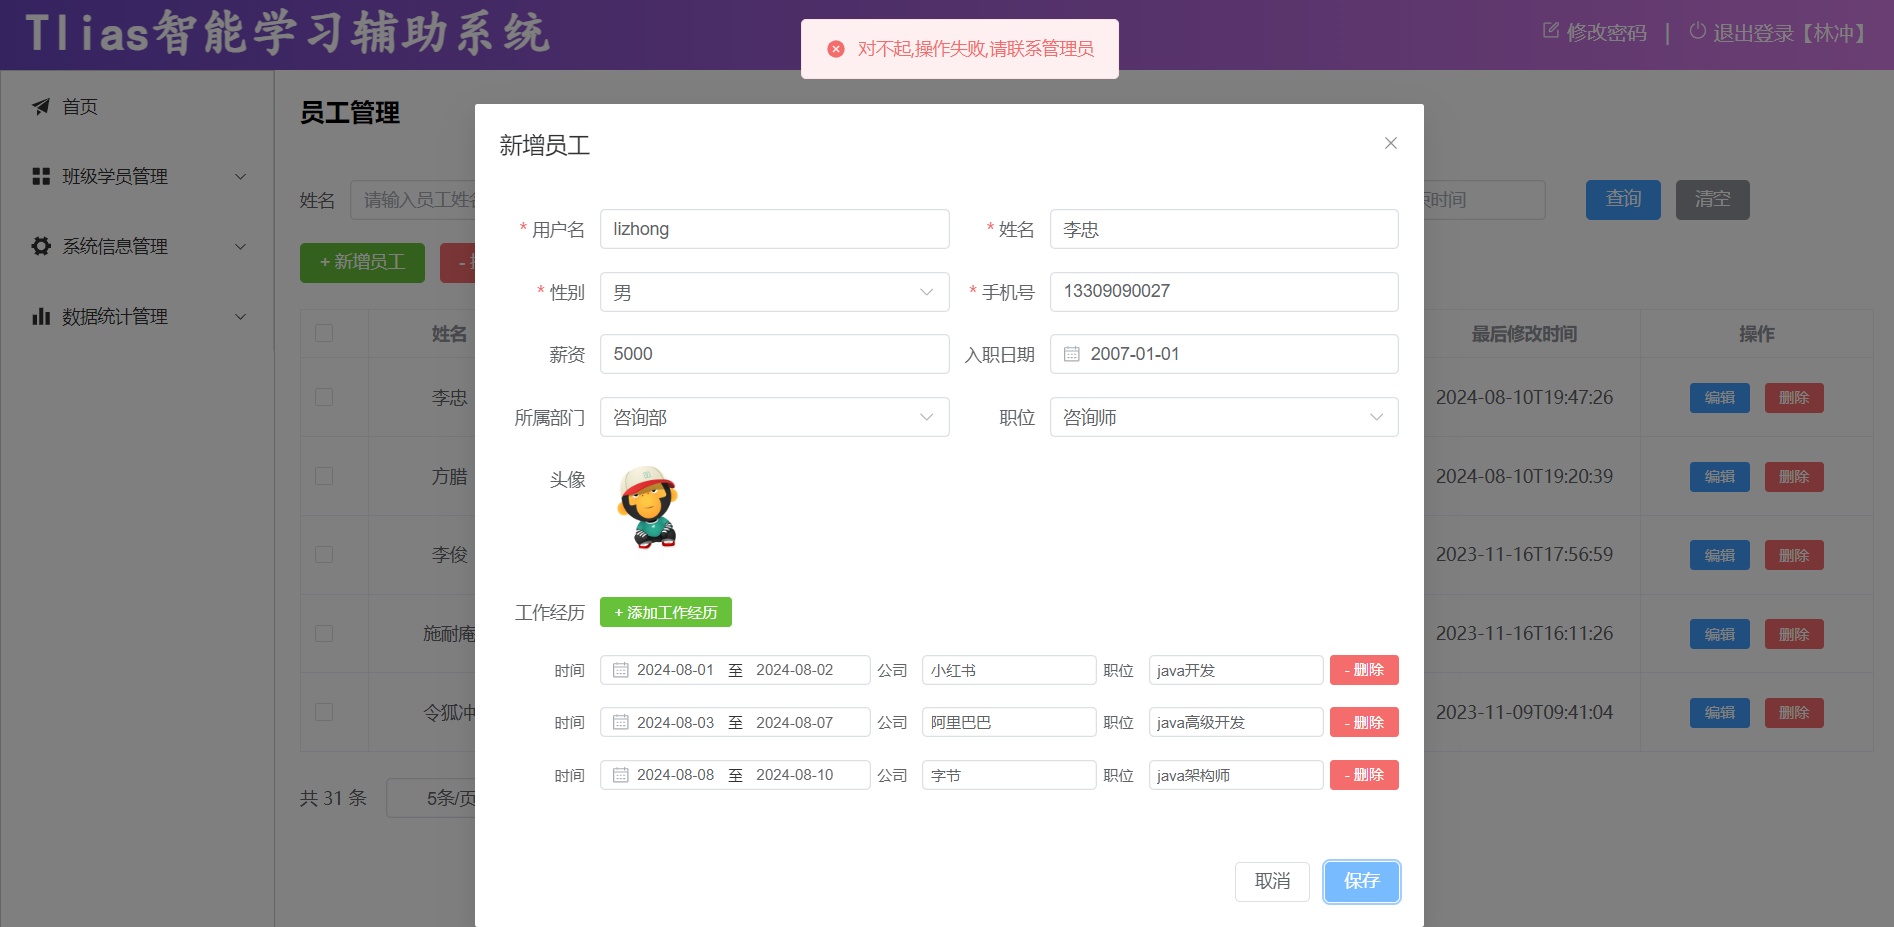

此时，我们可以看到，出现异常之后，异常已经被全局异常处理器捕获了。然后返回的错误信息，被前端程序正常解析，然后提示出了对应的错误提示信息。

> 以上就是全局异常处理器的使用，主要涉及到两个注解：
> 
> - @RestControllerAdvice  //表示当前类为全局异常处理器
> - @ExceptionHandler  //指定可以捕获哪种类型的异常进行处理


## 4 员工信息统计

员工管理的增删改查功能我们已开发完成，接下来，我们再来完成员工信息统计的接口开发。   对于这些图形报表的开发，其实呢，都是基于现成的一些图形报表的组件开发的，比如：Echarts、HighCharts等。

而报表的制作，主要是前端人员开发，引入对应的组件（比如：ECharts）即可。  服务端开发人员仅为其提供数据即可。

官网：https://echarts.apache.org/zh/index.html 

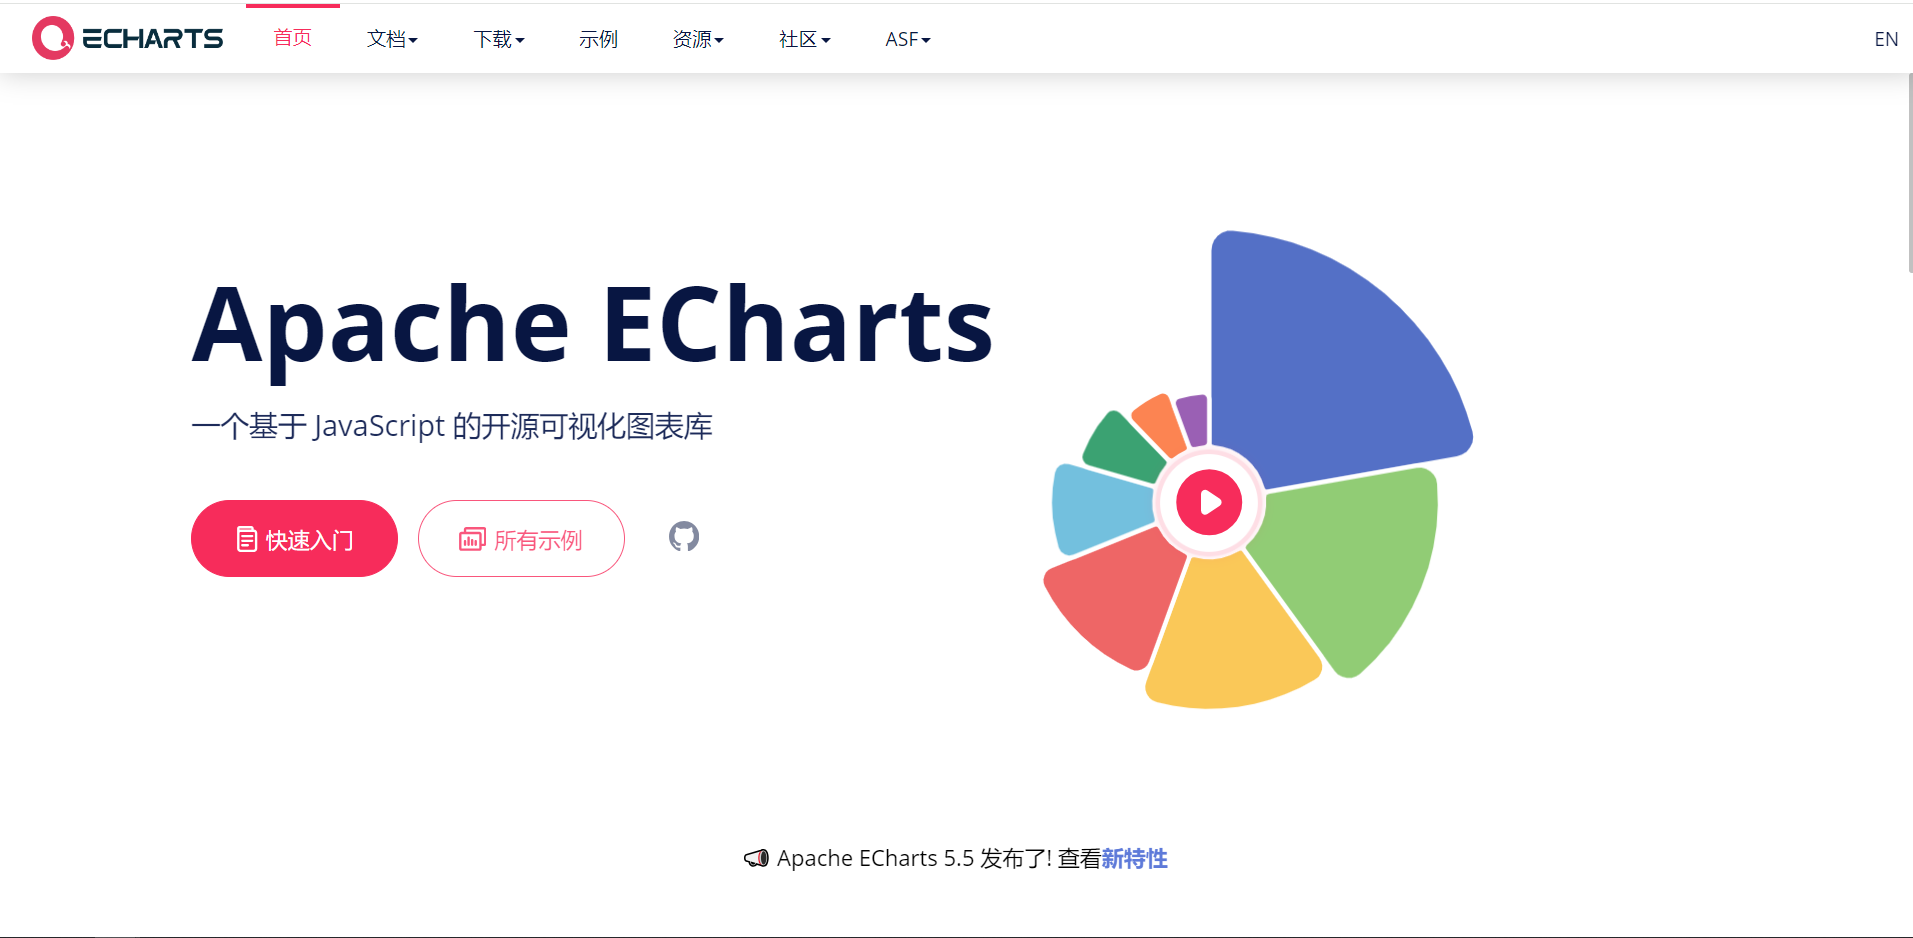


### 4.1 职位统计


#### 4.1.1 需求

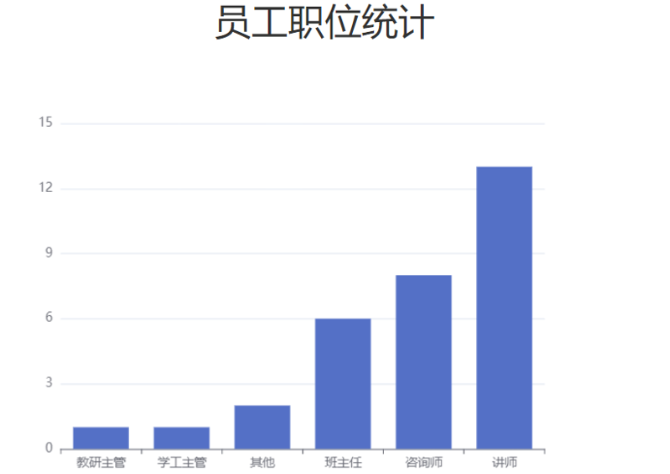

对于这类的图形报表，服务端要做的，就是为其提供数据即可。 我们可以通过官方的示例，看到提供的数据其实就是X轴展示的信息，和对应的数据。

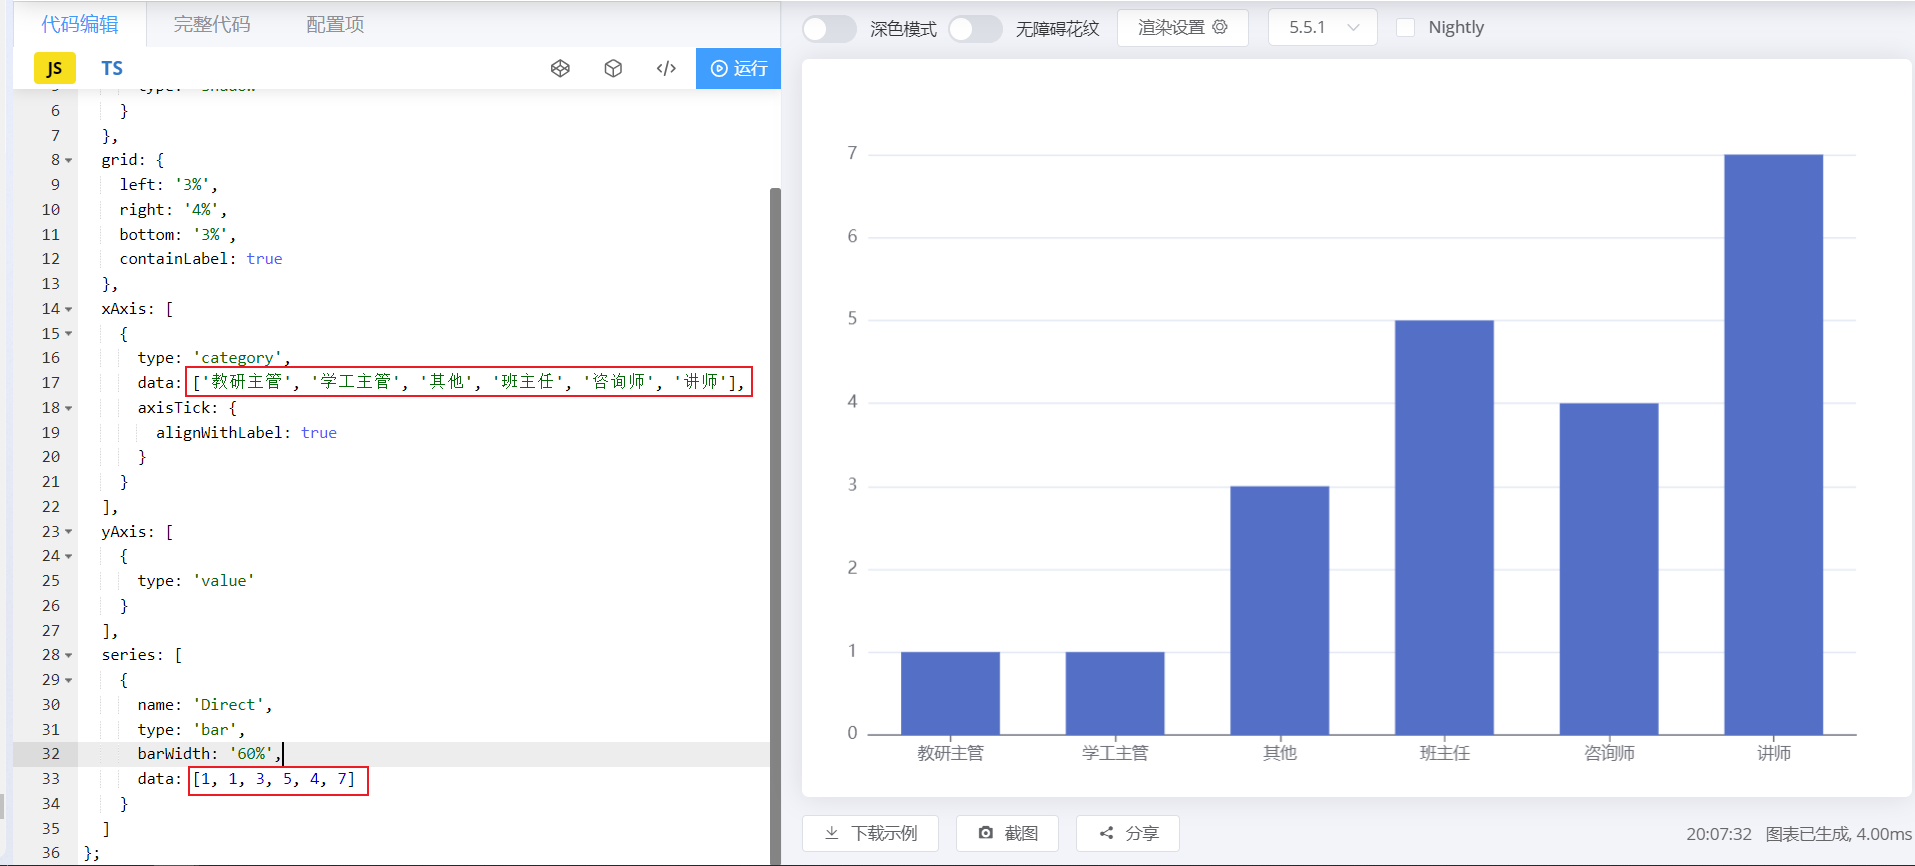


#### 4.1.2 接口描述

参照资料中提供的接口文档，查看 <strong><code>数据统计</code></strong>  -&gt; <strong><code>员工职位统计</code></strong><strong> </strong>接口的描述。


#### 4.1.3 代码实现

<strong>1). 定义</strong><strong>封装结果对象JobOption</strong>

在 <code>com.itheima.pojo</code> 包中定义实体类 <code>JobOption</code>

````java
package com.itheima.pojo;

import lombok.AllArgsConstructor;
import lombok.Data;
import lombok.NoArgsConstructor;

import java.util.List;

@Data
@NoArgsConstructor
@AllArgsConstructor
public class JobOption {
    private List jobList;
    private List dataList;
}
````

**补充｜类型。** 这里的原始 `List` 可以写成 `List<String> jobList` 和 `List<Long> dataList`（实际计数类型以数据库驱动返回值为准），避免后续强制转换。

<strong>1). 定义ReportController，并添加</strong><strong>方法</strong><strong>。</strong>

````java
@Slf4j
@RequestMapping("/report")
@RestController
public class ReportController {

    @Autowired
    private ReportService reportService;

    /**
     * 统计各个职位的员工人数
     */
    @GetMapping("/empJobData")
    public Result getEmpJobData(){
        log.info("统计各个职位的员工人数");
        JobOption jobOption = reportService.getEmpJobData();
        return Result.success(jobOption);
    }
}
````

<strong>2). 定义ReportService接口，并添加接口方法。</strong>

````java
public interface ReportService {
    /**
     * 统计各个职位的员工人数
     * @return
     */
    JobOption getEmpJobData();
}
````

<strong>3). 定义ReportServiceImpl实现类，并实现方法</strong>

````java
@Service
public class ReportServiceImpl implements ReportService {

    @Autowired
    private EmpMapper empMapper;
        
    @Override
    public JobOption getEmpJobData() {
        List<Map<String,Object>> list = empMapper.countEmpJobData();
        List<Object> jobList = list.stream().map(dataMap -> dataMap.get("pos")).toList();
        List<Object> dataList = list.stream().map(dataMap -> dataMap.get("total")).toList();
        return new JobOption(jobList, dataList);
    }
}
````

<strong>4). </strong><strong>定义EmpMapper 接口</strong>

统计的是员工的信息，所以需要操作的是员工表。 所以代码我们就写在 <code>EmpMapper</code> 接口中即可。

````java
/**
 * 统计各个职位的员工人数
 */
@MapKey("pos")
List<Map<String,Object>> countEmpJobData();
````

**勘误｜`@MapKey`。** 当前返回类型是 `List<Map<String, Object>>`，不需要 `@MapKey`；该注解主要用于返回外层 `Map<K,V>` 时指定键。直接保留 `List<Map<String, Object>> countEmpJobData();` 即可。性别统计 Mapper 同理。

> 如果查询的记录往Map中封装，可以通过@MapKey注解指定返回的map中的唯一标识是那个字段。【也可以不指定】

<strong>5). 定义EmpMapper.xml</strong>

````xml
<!-- 统计各个职位的员工人数 -->
<select id="countEmpJobData" resultType="java.util.Map">
    select
    (case job when 1 then '班主任' 
                     when 2 then '讲师' 
                     when 3 then '学工主管' 
                     when 4 then '教研主管' 
                     when 5 then '咨询师' 
                     else '其他' end)  pos,
    count(*) total
    from emp group by job
    order by total
</select>
````

**补充｜统计口径。** `CASE` 把未列出的职位统一标为“其他”，但 `GROUP BY job` 仍按原始职位分组；存在多个未知职位值时会出现多个“其他”行。可先在子查询中映射标签，再按标签分组。`ORDER BY total` 默认为升序，图表需要固定次序时应显式指定。

> <strong>case流程控制函数：</strong>
> 
> - 语法一：case when cond1 then res1 &#91; when cond2 then res2 &#93; else res end ;
> - 含义：如果 cond1 成立， 取 res1。  如果 cond2 成立，取 res2。 如果前面的条件都不成立，则取 res。
> 
> - 语法二（仅适用于等值匹配）：case expr when val1 then res1 &#91; when val2 then res2 &#93; else res end ;
> - 含义：如果 expr 的值为 val1 ， 取 res1。  如果  expr 的值为 val2 ，取 res2。 如果前面的条件都不成立，则取 res。


#### 4.1.4 Apifox测试

重新启动服务，打开Apifox进行测试。

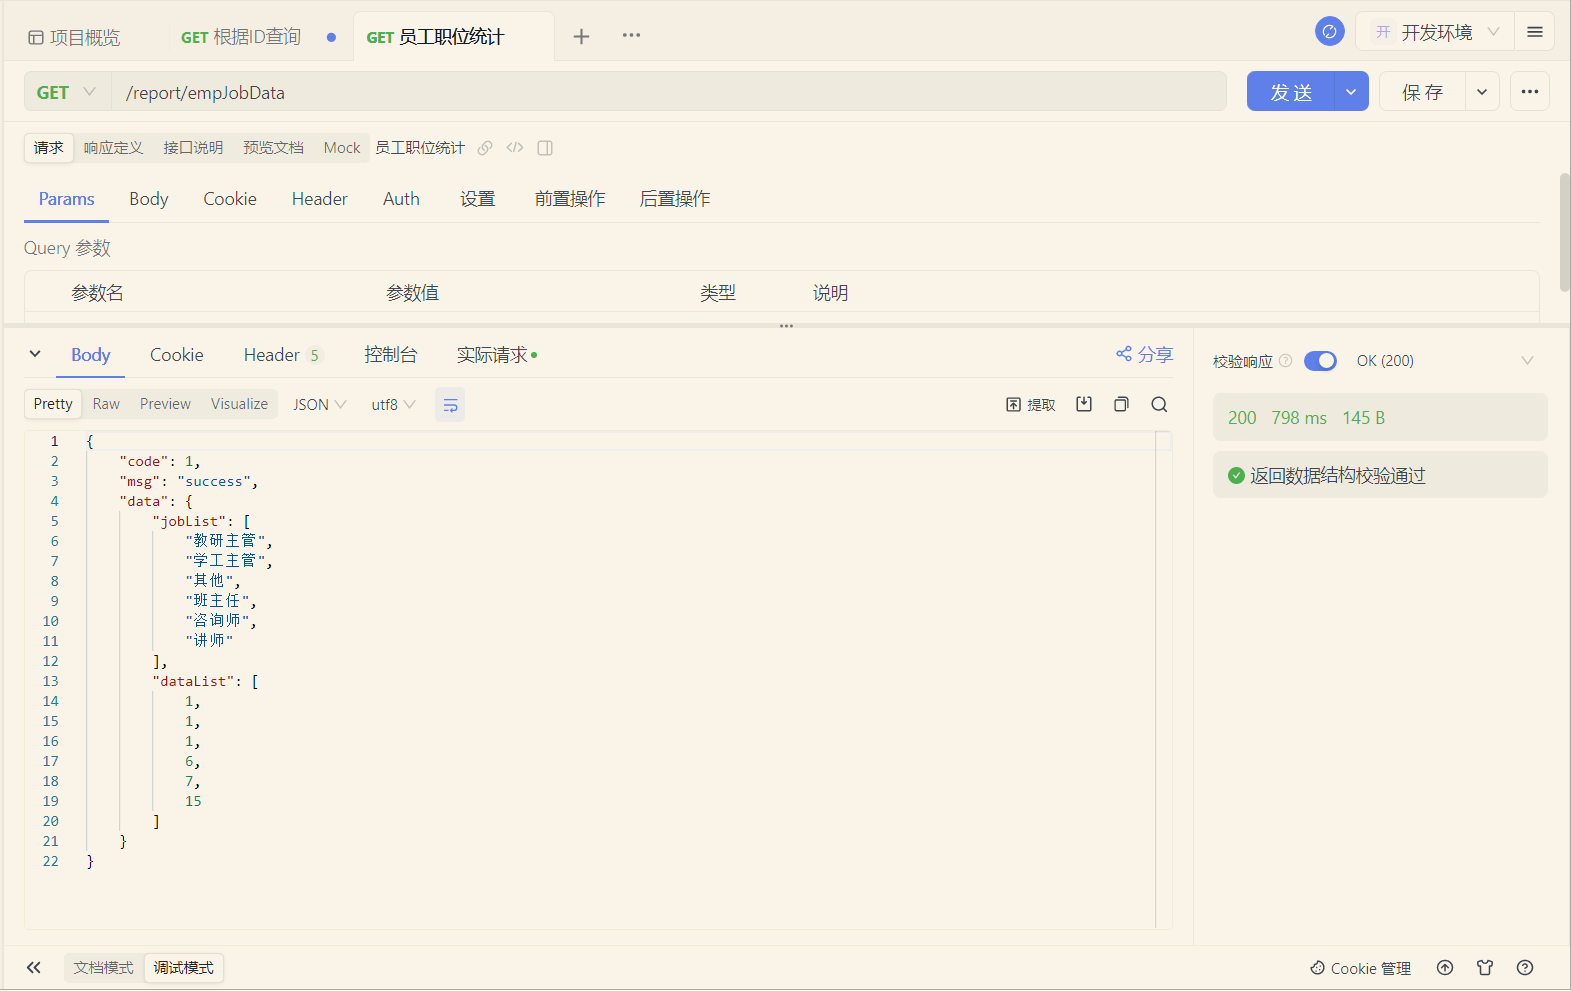


#### 4.1.5 联调测试

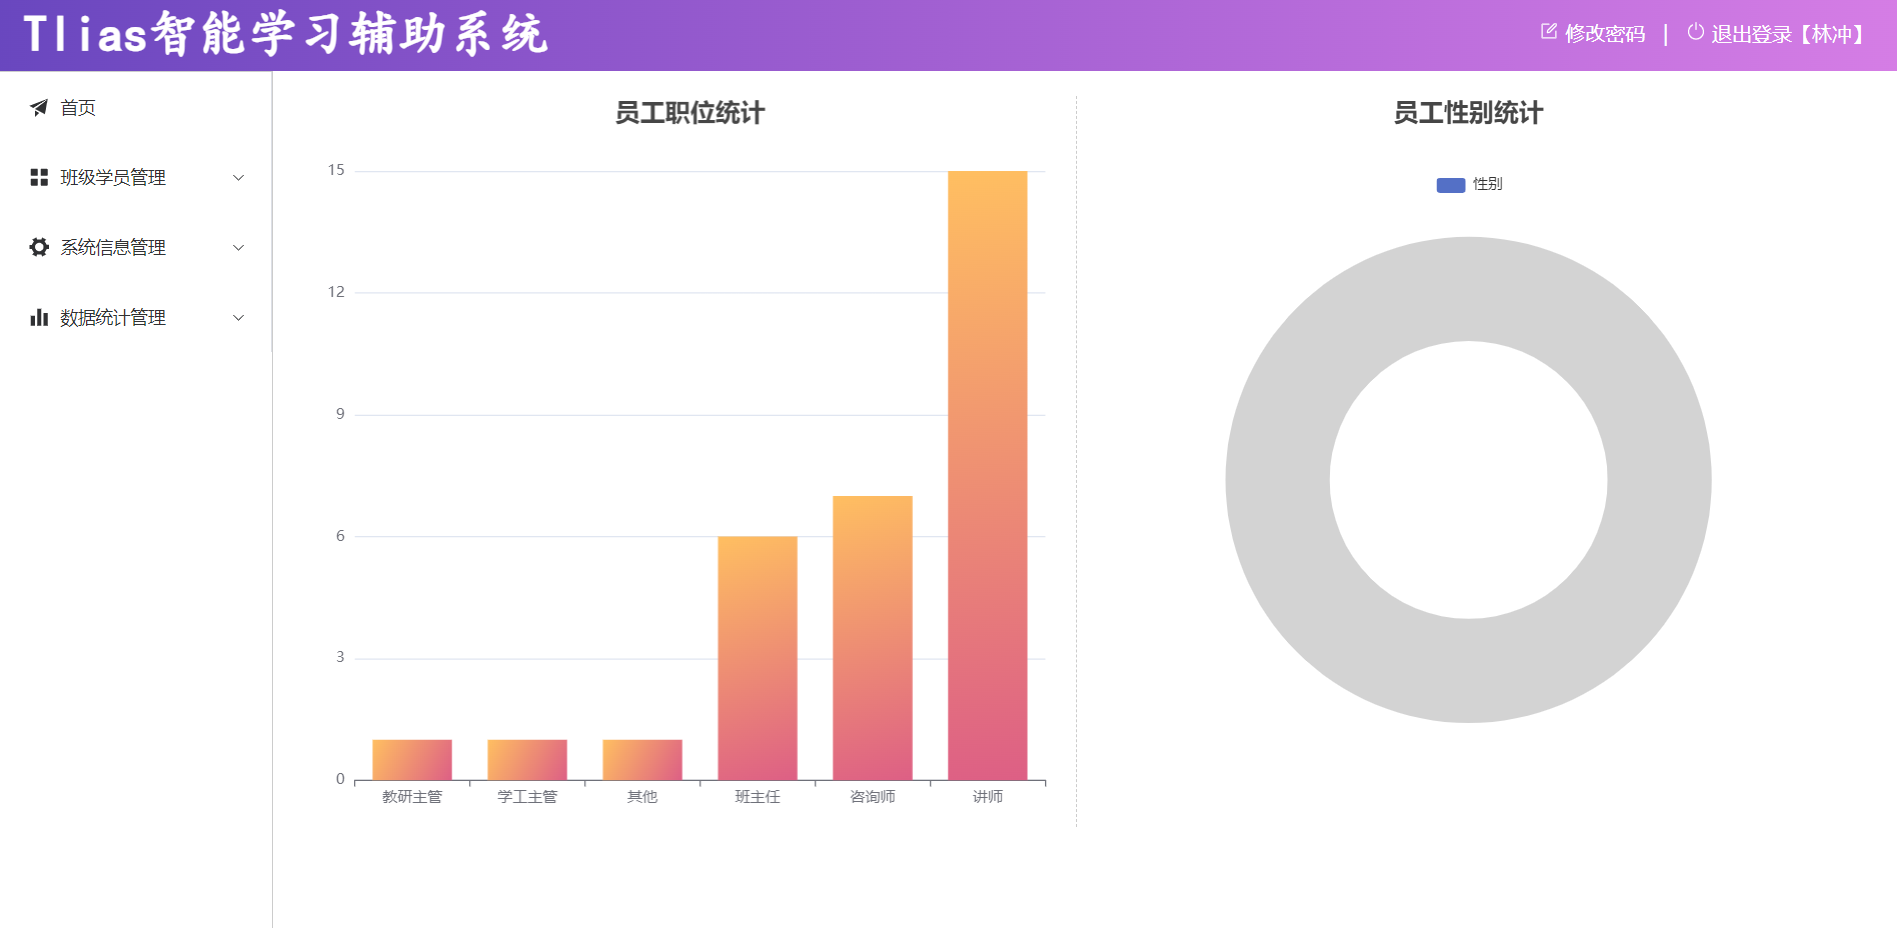


### 4.2 性别统计


#### 4.2.1 需求

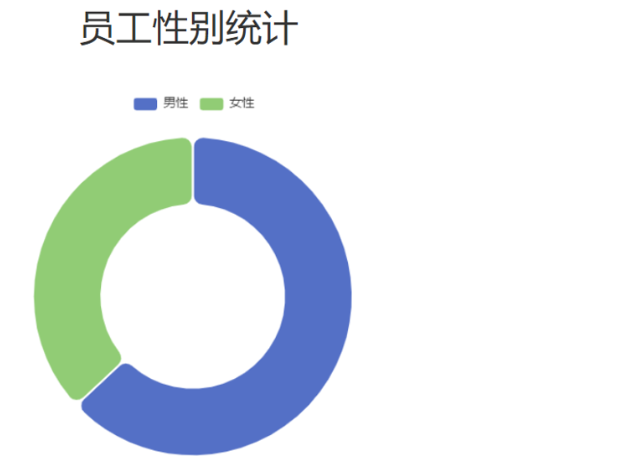

对于这类的图形报表，服务端要做的，就是为其提供数据即可。 我们可以通过官方的示例，看到提供的数据就是一个json格式的数据。

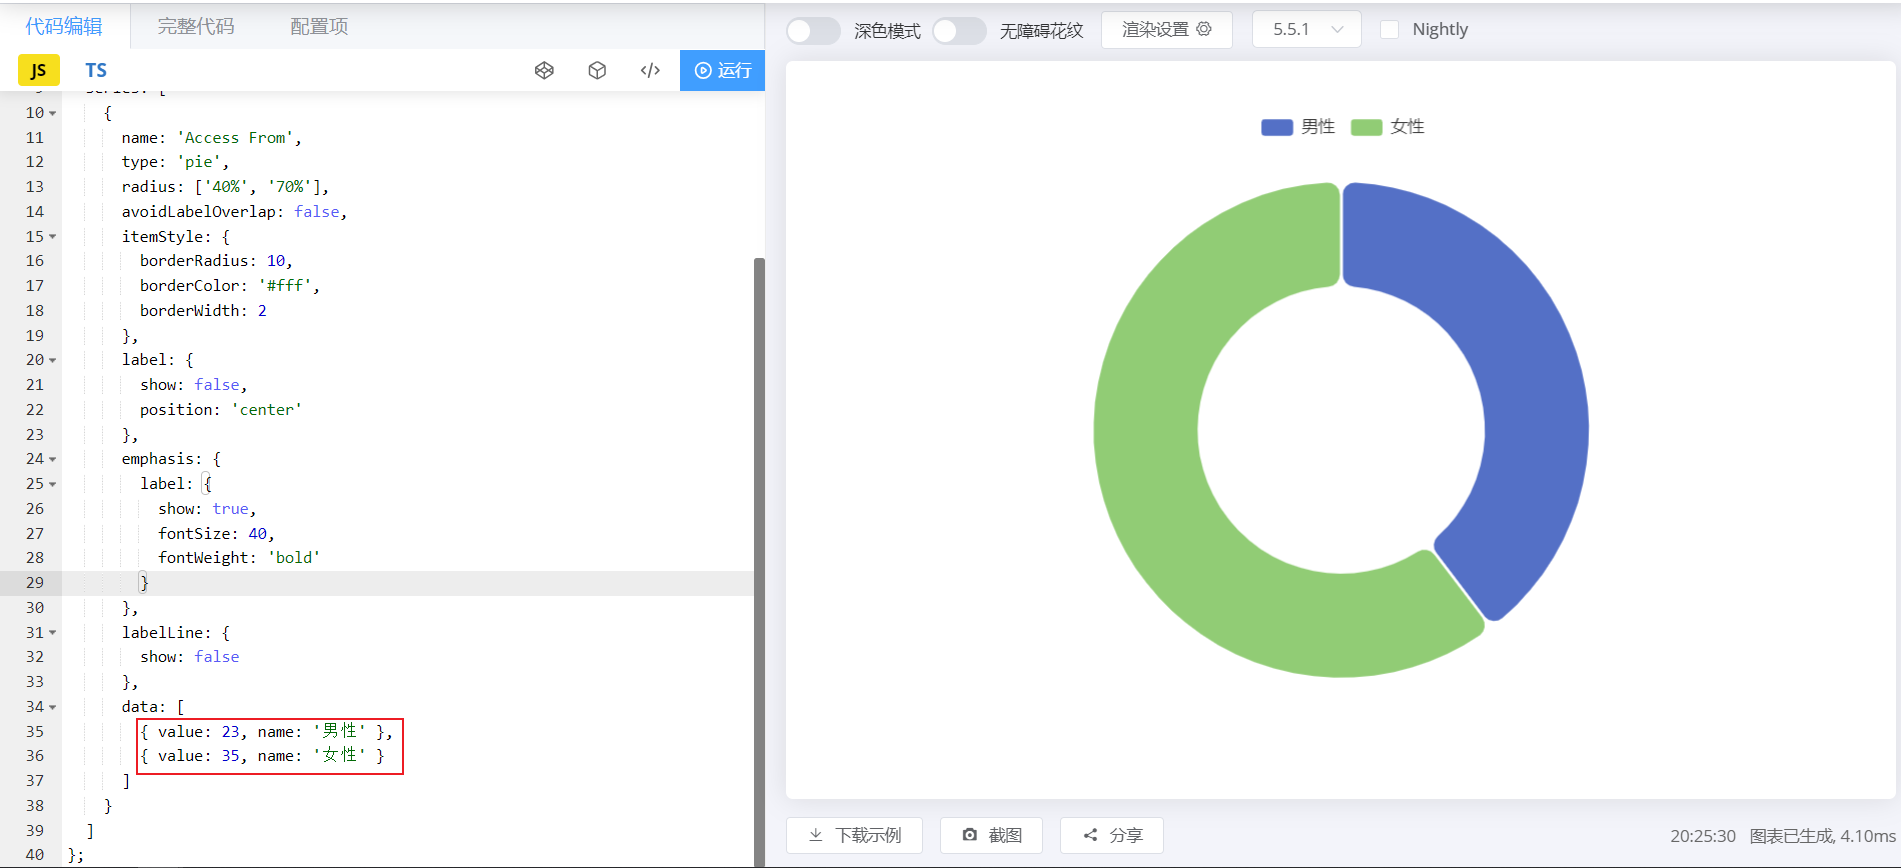


#### 4.2.2 接口描述

参照资料中提供的接口文档，查看 <strong><code>数据统计</code></strong>  -&gt; <strong><code>员工性别统计</code></strong><strong> </strong>接口的描述。


#### 4.2.3 代码实现

<strong>1). 在ReportController，添加方法。</strong>

````java
/**
 * 统计员工性别信息
 */
@GetMapping("/empGenderData")
public Result getEmpGenderData(){
    log.info("统计员工性别信息");
    List<Map> genderList = reportService.getEmpGenderData();
    return Result.success(genderList);
}
````

<strong>2). 在ReportService接口，添加接口方法。</strong>

````java
/**
 * 统计员工性别信息
 */
List<Map> getEmpGenderData();
````

<strong>3). 在ReportServiceImpl实现类，实现方法</strong>

````java
@Override
public List<Map> getEmpGenderData() {
    return empMapper.countEmpGenderData();
}
````

<strong>4). 定义EmpMapper 接口</strong>

统计的是员工的信息，所以需要操作的是员工表。 所以代码我们就写在 <code>EmpMapper</code> 接口中即可。

````java
/**
 * 统计员工性别信息
 */
@MapKey("name")
List<Map> countEmpGenderData();
````

<strong>5). 定义EmpMapper.xml</strong>

````xml
<!-- 统计员工的性别信息 -->
<select id="countEmpGenderData" resultType="java.util.Map">
    select
    if(gender = 1, '男', '女') as name,
    count(*) as value
    from emp group by gender ;
</select>
````

**补充｜性别分组。** `IF(gender=1,'男','女')` 会把 `NULL` 或其他编码归入“女”。若数据可能含未知值，改用 `CASE WHEN gender=1 THEN '男' WHEN gender=2 THEN '女' ELSE '未知' END`，并按相同口径分组。

> if函数语法：<code>if(条件, 条件为true取值, 条件为false取值)</code>
> 
> ifnull函数语法：<code>ifnull(expr, val1)</code>    如果expr不为null，取自身，否则取val1


#### 4.2.4 Apifox测试

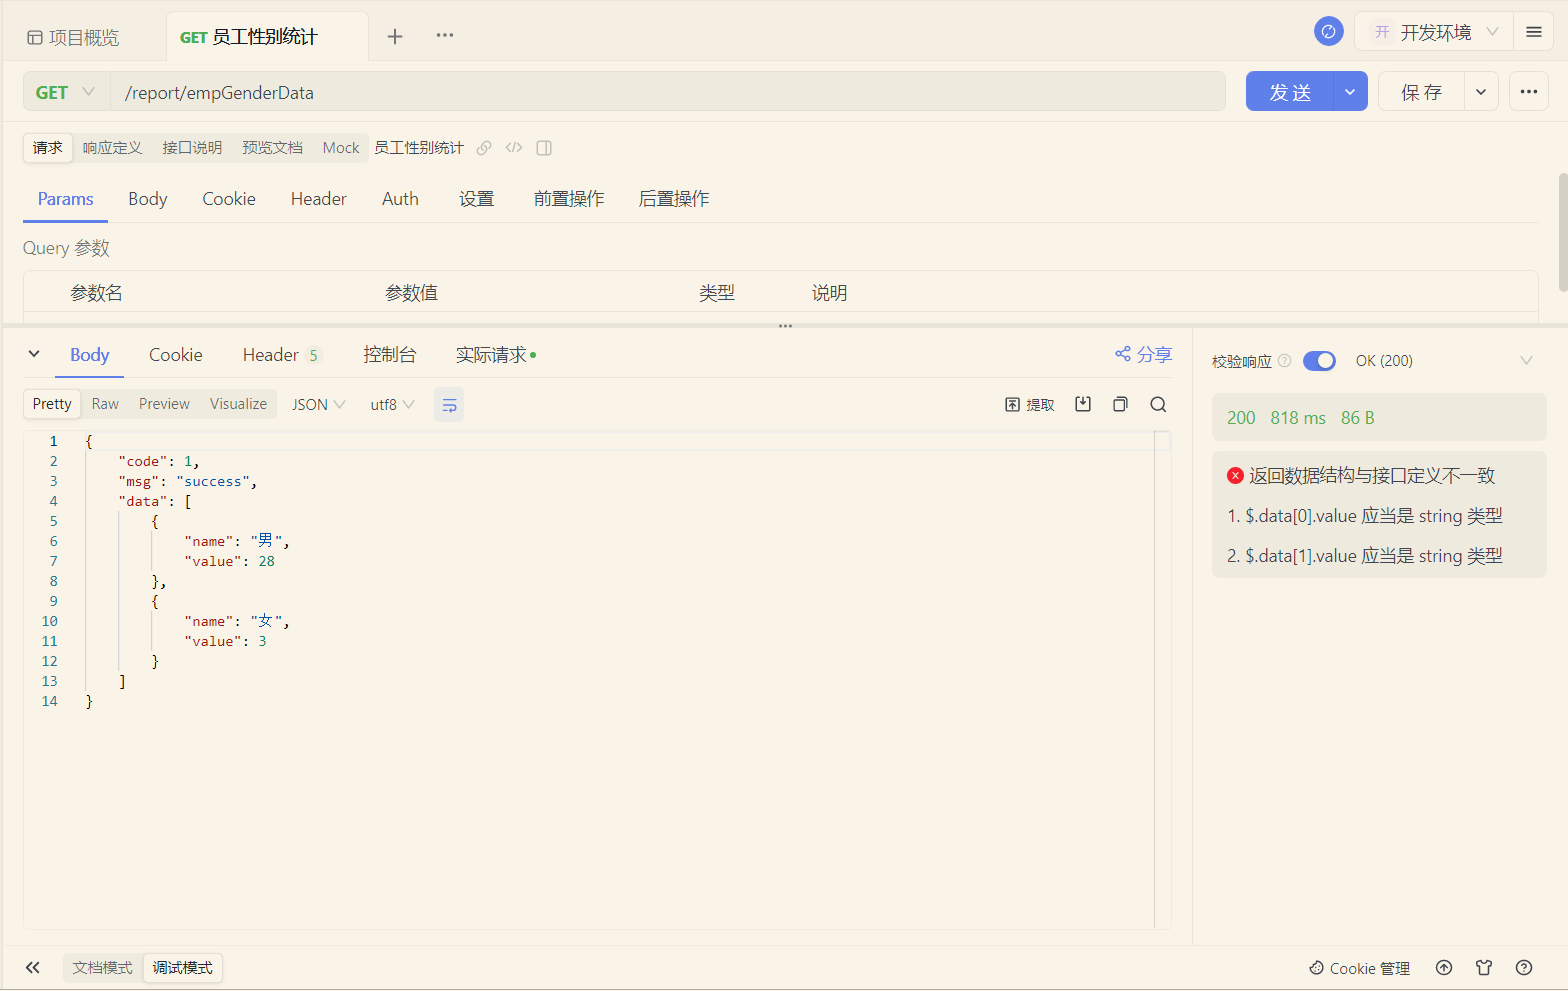


#### 4.2.5 联调测试

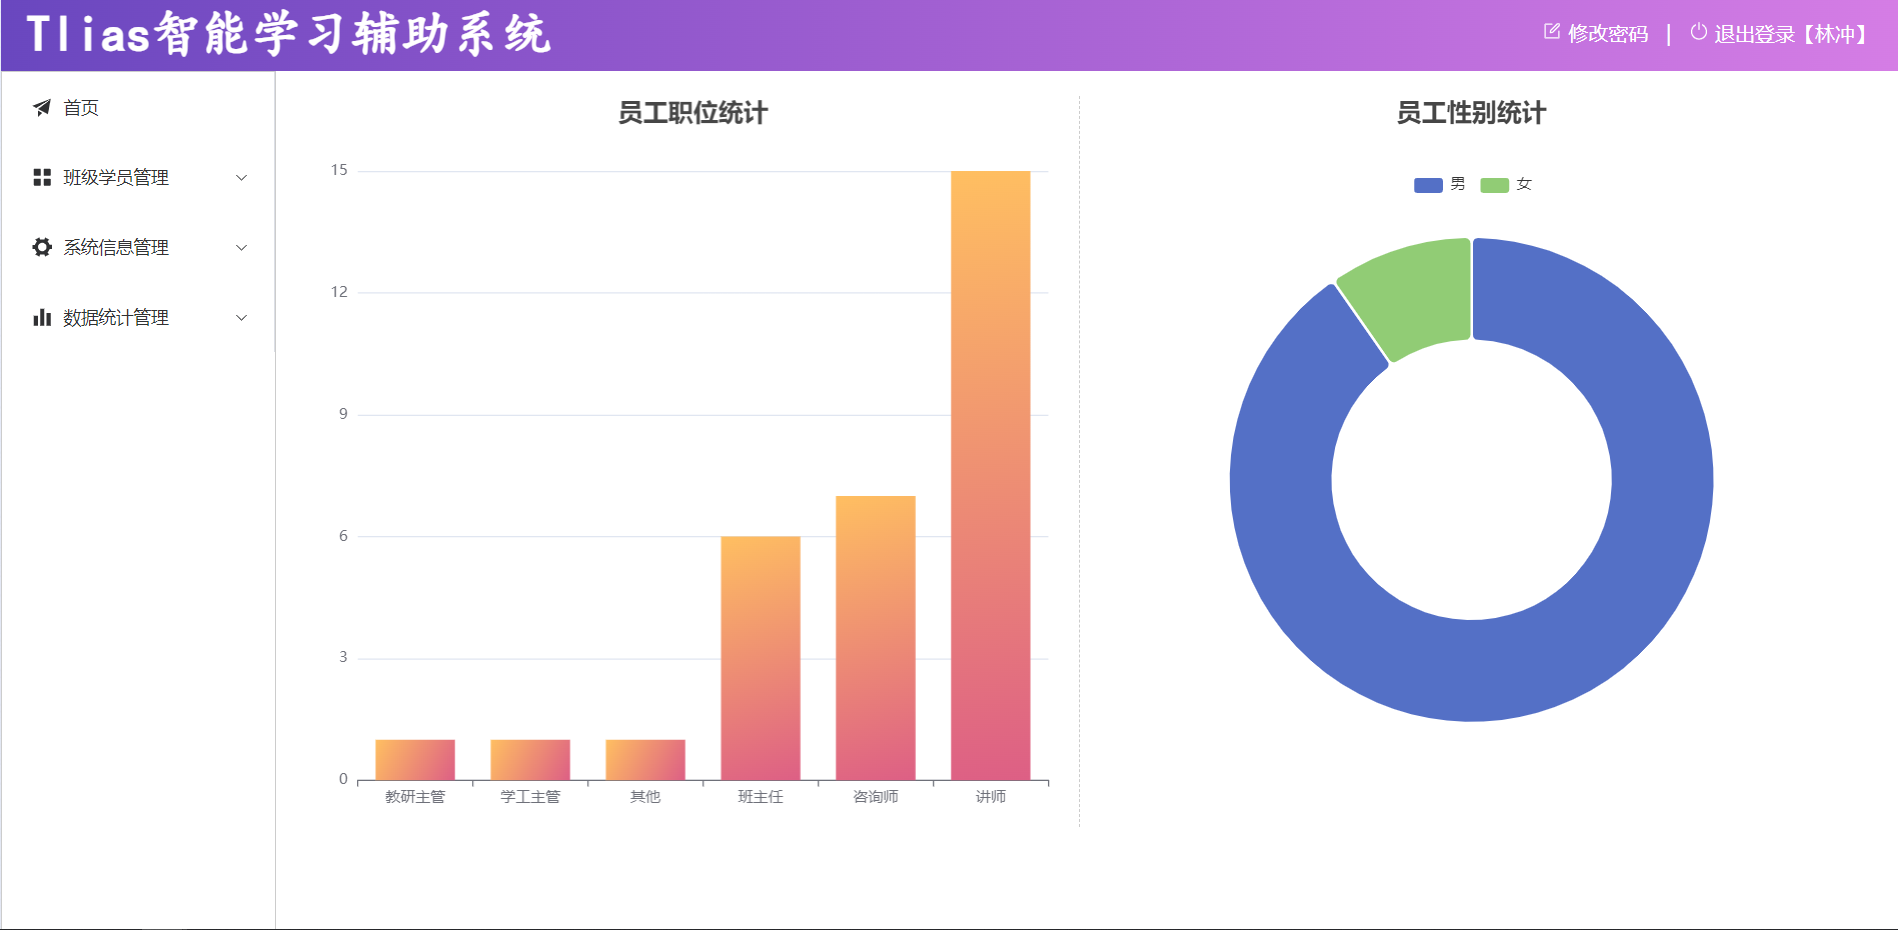


## 5 补充：接口与事务核对

按讲义中的控制器映射，`EmpController` 类级路径沿用前章的 `/emps`，`ReportController` 类级路径为 `/report`。这些路径要与实际项目及接口文档核对。

| 操作 | 方法与路径 | 关键输入 | 成功后检查 |
| --- | --- | --- | --- |
| 批量删除 | `DELETE /emps?ids=1,2` | 逗号分隔的员工 ID | `emp` 和 `emp_expr` 对应记录都消失 |
| 查询回显 | `GET /emps/{id}` | 路径 ID | 基本信息与 `exprList` 一起返回，不返回密码 |
| 修改员工 | `PUT /emps` | 员工字段和完整 `exprList` | 基本信息更新，旧经历被新列表替换 |
| 职位统计 | `GET /report/empJobData` | 无 | `jobList` 与 `dataList` 按相同顺序对应 |
| 性别统计 | `GET /report/empGenderData` | 无 | 返回 `{name, value}` 数组 |

建议在测试数据库中验证四类情况：单条/多条删除、员工无工作经历的回显、修改中途失败的事务回滚、手机号重复时的统一错误响应。还应测试空 ID 列表和未知性别值，确认接口边界与统计口径。
